## Step 1 — Import libraries

In [1]:
# Uncomment if a package is missing (e.g. fresh Colab / local install)
# !pip install pandas numpy matplotlib seaborn scipy scikit-learn plotly

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from scipy.stats import skew

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
print("Libraries imported.")

Libraries imported.


## Step 2 — Load the dataset
Place `Country-data.csv` (from the Kaggle link above) in the same folder as this notebook. If the file is not found, a public GitHub copy of the same file is used.

In [2]:
LOCAL_PATH = "Country-data.csv"
URL = ("https://raw.githubusercontent.com/Janice-Afi/"
       "Help-International-Clustering-Project/main/Country-data.csv")

if os.path.exists(LOCAL_PATH):
    df_raw = pd.read_csv(LOCAL_PATH)
    print("Loaded local file:", LOCAL_PATH)
else:
    df_raw = pd.read_csv(URL)
    print("Local file not found - loaded from GitHub copy")

print("Shape (rows, columns):", df_raw.shape)

Local file not found - loaded from GitHub copy
Shape (rows, columns): (167, 10)


## Step 3 — View and analyse the data

| Column | Meaning |
|---|---|
| `country` | Country name |
| `child_mort` | Deaths of children under 5 per 1,000 live births |
| `exports` | Exports per capita (% of GDP per capita) |
| `health` | Total health spending per capita (% of GDP per capita) |
| `imports` | Imports per capita (% of GDP per capita) |
| `income` | Net income per person |
| `inflation` | Annual growth rate of total GDP (%) |
| `life_expec` | Life expectancy at birth (years) |
| `total_fer` | Children born to each woman |
| `gdpp` | GDP per capita (USD) |

In [3]:
df_raw.head(10)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.440,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.490,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.100,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.440,76.8,2.13,12200
5,Argentina,14.5,18.9,8.10,16.0,18700,20.900,75.8,2.37,10300
6,Armenia,18.1,20.8,4.40,45.3,6700,7.770,73.3,1.69,3220
7,Australia,4.8,19.8,8.73,20.9,41400,1.160,82.0,1.93,51900
8,Austria,4.3,51.3,11.00,47.8,43200,0.873,80.5,1.44,46900
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.800,69.1,1.92,5840


In [4]:
df_raw.tail(5)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
162,Vanuatu,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,Venezuela,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,Vietnam,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,Yemen,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310
166,Zambia,83.1,37.0,5.89,30.9,3280,14.00,52.0,5.40,1460


In [5]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), str(1)
memory usage: 13.2 KB


In [6]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
child_mort,167.0,38.27,40.33,2.60,8.25,19.30,62.10,208.00
exports,167.0,41.11,27.41,0.11,23.80,35.00,51.35,200.00
health,167.0,6.82,2.75,1.81,4.92,6.32,8.60,17.90
imports,167.0,46.89,24.21,0.07,30.20,43.30,58.75,174.00
income,167.0,17144.69,19278.07,609.00,3355.00,9960.00,22800.00,125000.00
inflation,167.0,7.78,10.57,-4.21,1.81,5.39,10.75,104.00
life_expec,167.0,70.56,8.89,32.10,65.30,73.10,76.80,82.80
total_fer,167.0,2.95,1.51,1.15,1.80,2.41,3.88,7.49
gdpp,167.0,12964.16,18328.70,231.00,1330.00,4660.00,14050.00,105000.00


In [7]:
features = [c for c in df_raw.columns if c != "country"]

print("Missing values per column:\n", df_raw.isna().sum(), sep="")
print("\nDuplicate rows     :", df_raw.duplicated().sum())
print("Duplicate countries:", df_raw["country"].duplicated().sum())
print("\nNumber of countries:", df_raw["country"].nunique())
print("\nSkewness of each indicator:")
print(df_raw[features].apply(skew).round(2).sort_values(ascending=False).to_string())

Missing values per column:
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Duplicate rows     : 0
Duplicate countries: 0

Number of countries: 167

Skewness of each indicator:
inflation     5.11
exports       2.42
income        2.21
gdpp          2.20
imports       1.89
child_mort    1.44
total_fer     0.96
health        0.70
life_expec   -0.96


In [8]:
# Outlier count per indicator using the 1.5 x IQR rule
q1, q3 = df_raw[features].quantile(0.25), df_raw[features].quantile(0.75)
iqr = q3 - q1
outliers = ((df_raw[features] < q1 - 1.5 * iqr) | (df_raw[features] > q3 + 1.5 * iqr)).sum()
outliers.to_frame("outlier_count").T

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
outlier_count,4,5,2,4,8,5,3,1,25


**Observations:** no missing values and no duplicates. Money-based indicators (`gdpp`, `income`, `exports`, `imports`) are highly right-skewed with many outliers. These outliers are real (very rich countries), so they are not removed. Instead they are handled with a power transform in Step 5.

## Step 4 — Visualisation / Exploratory Data Analysis

### 4.1 Distribution of each indicator

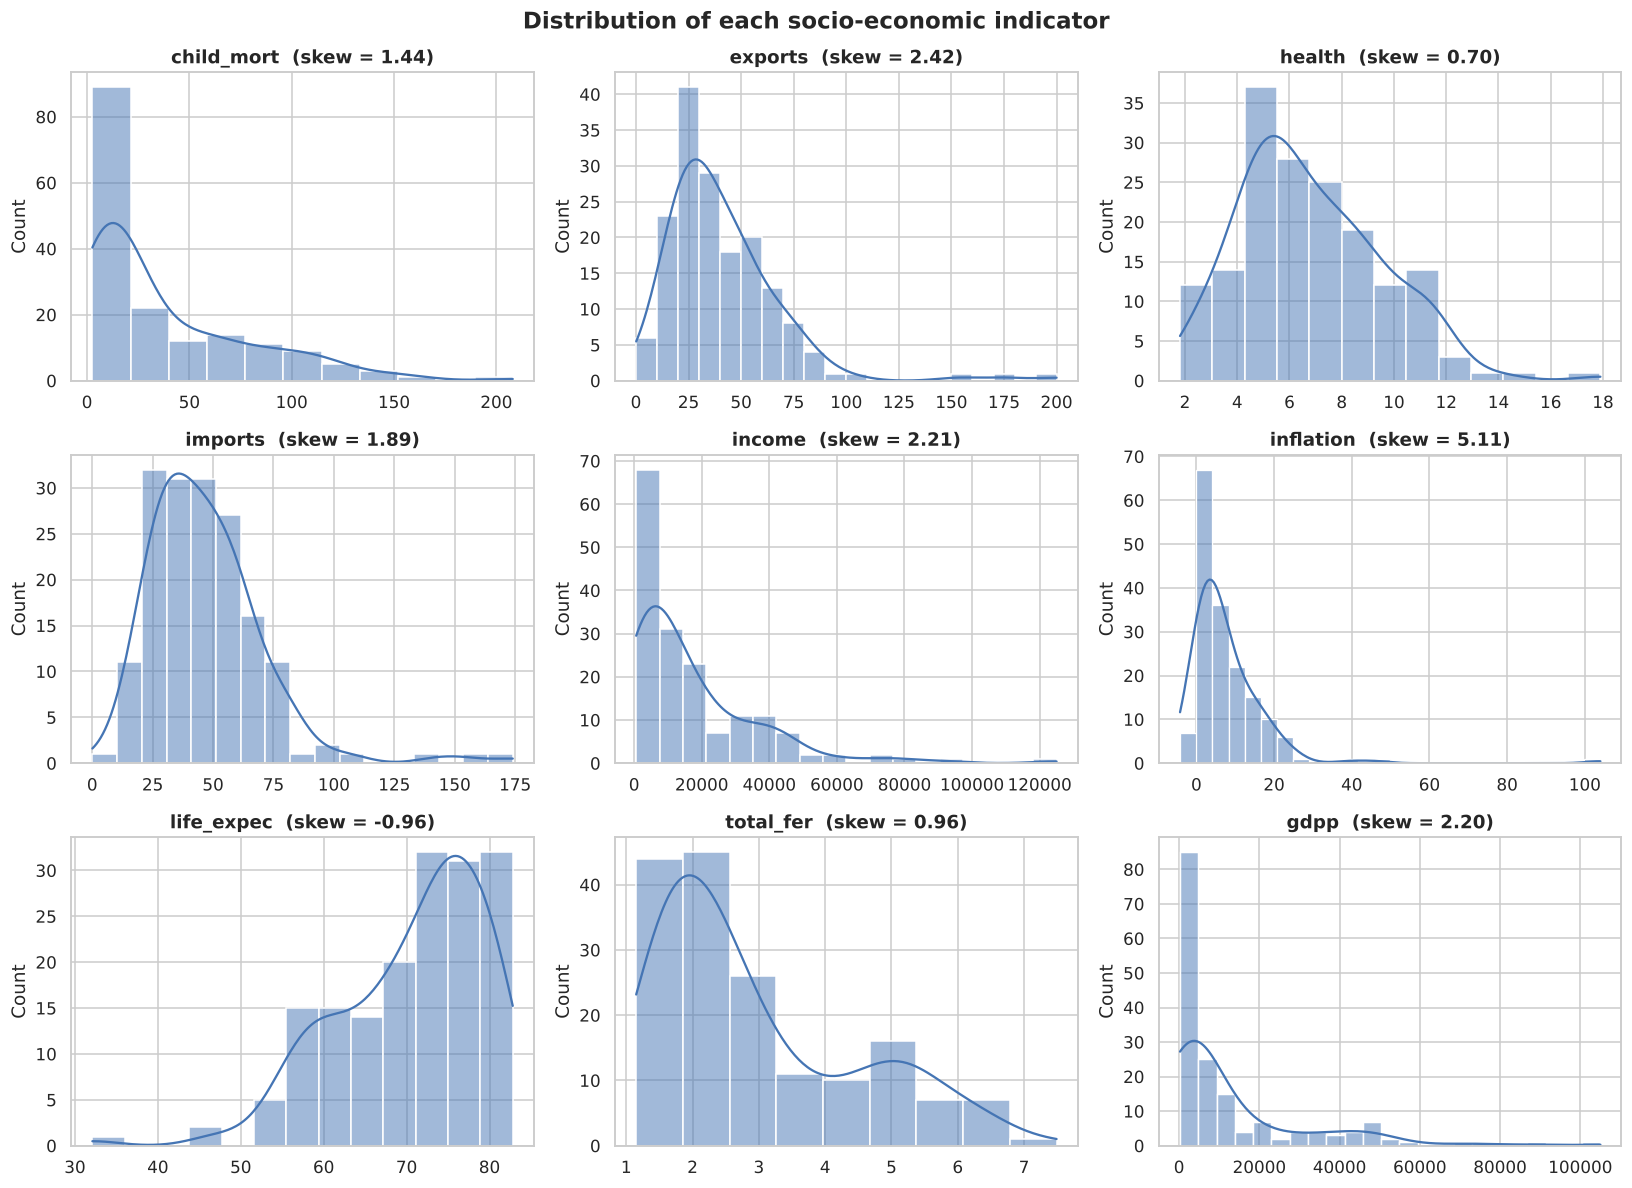

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df_raw[col], kde=True, ax=ax, color="#4575b4", edgecolor="white")
    ax.set_title(f"{col}  (skew = {skew(df_raw[col]):.2f})")
    ax.set_xlabel("")
fig.suptitle("Distribution of each socio-economic indicator", fontsize=15, fontweight="bold")z
plt.tight_layout()
plt.show()

### 4.2 Box plots (outliers)

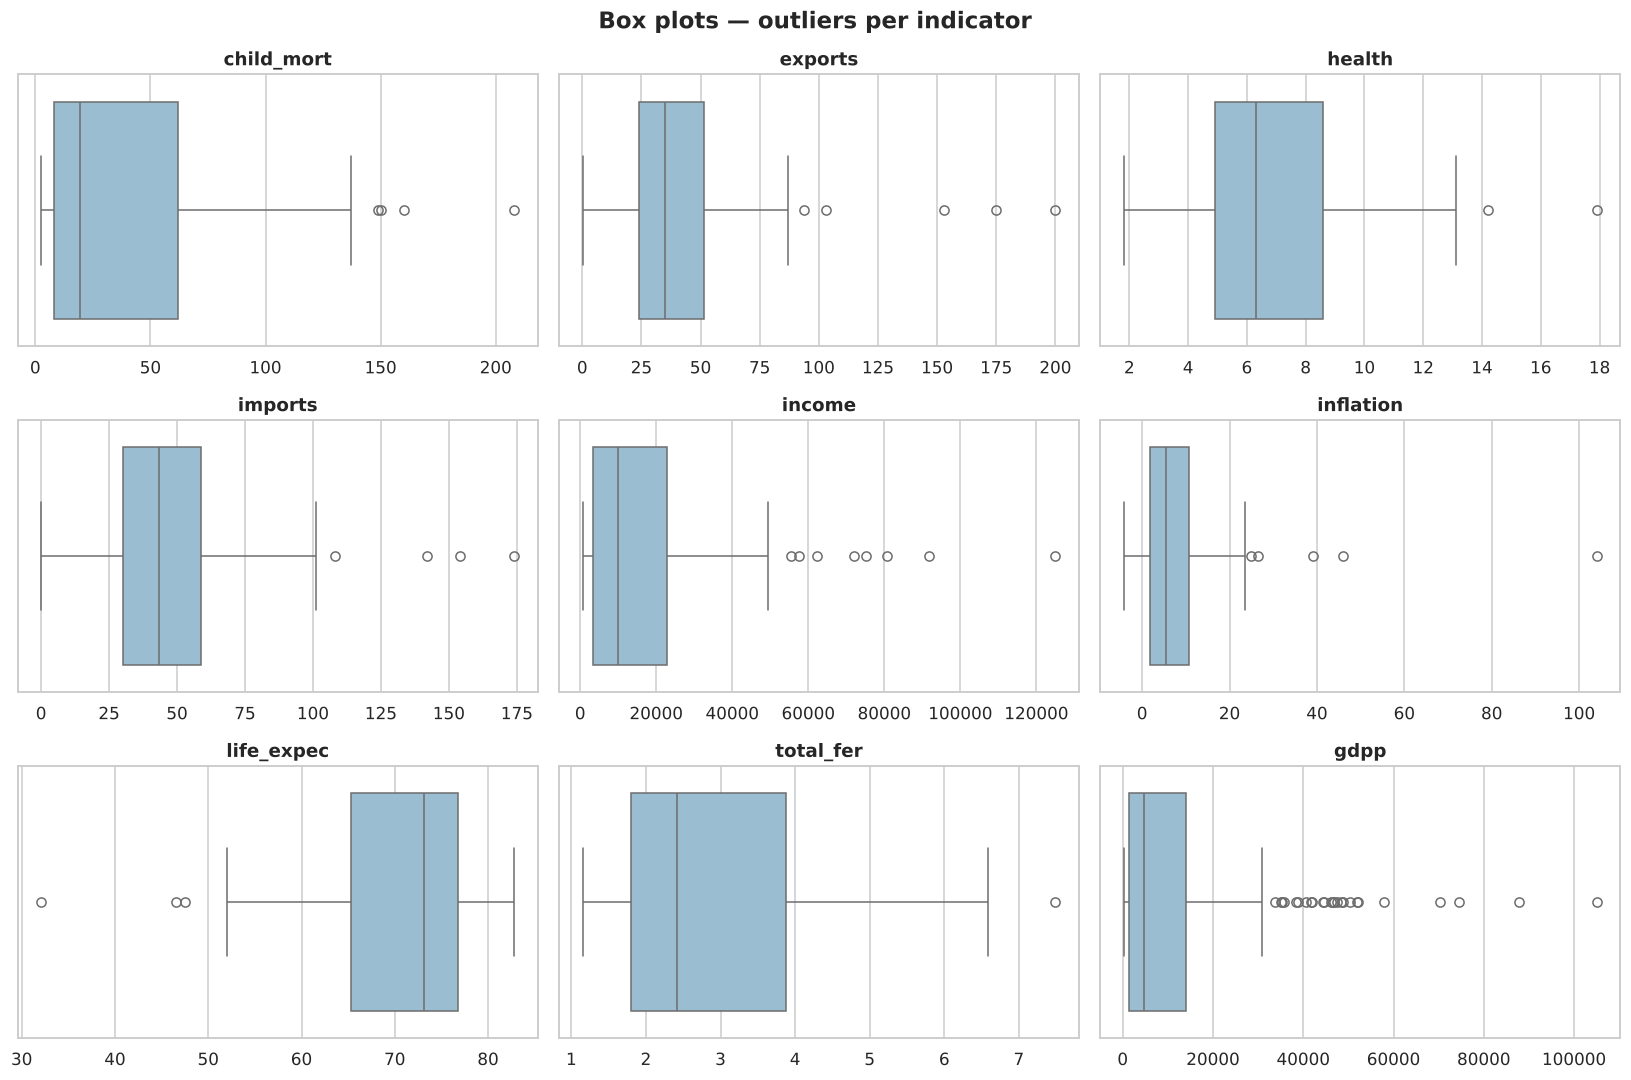

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x=df_raw[col], ax=ax, color="#91bfdb")
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Box plots — outliers per indicator", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.3 Correlation heatmap

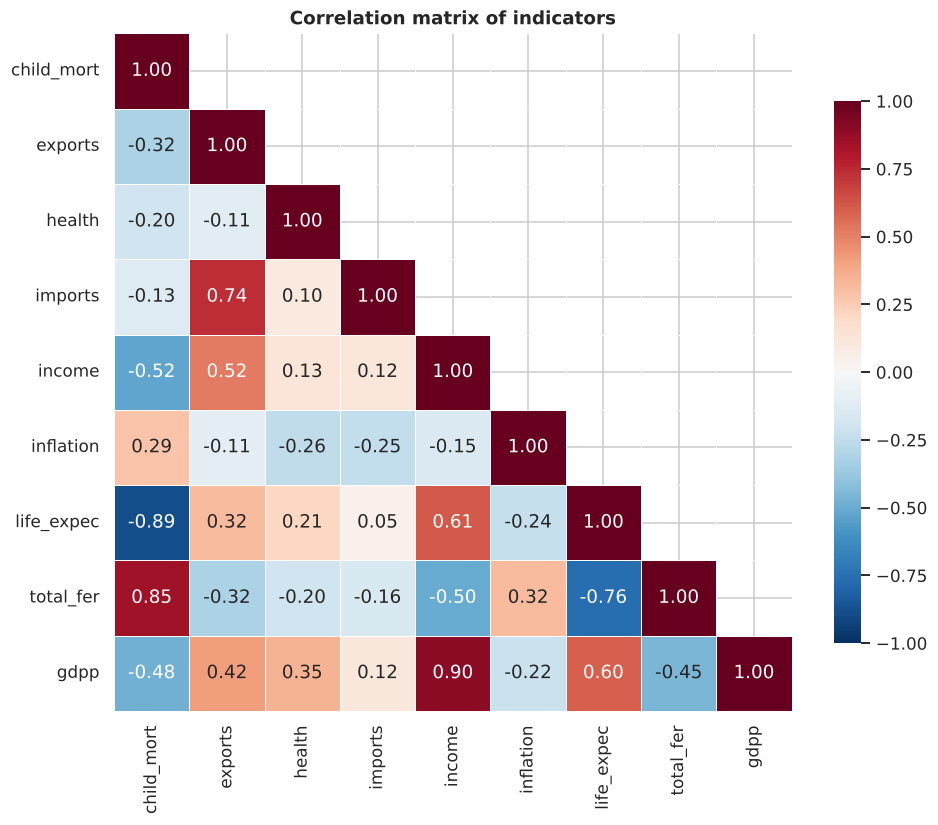

In [11]:
plt.figure(figsize=(10, 8))
corr = df_raw[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix of indicators")
plt.show()

Strong correlations (`gdpp`–`income`, `child_mort`–`life_expec`, `child_mort`–`total_fer`) show that several columns measure the same thing. This is why PCA is used before clustering.

### 4.4 Pair plot of the key indicators

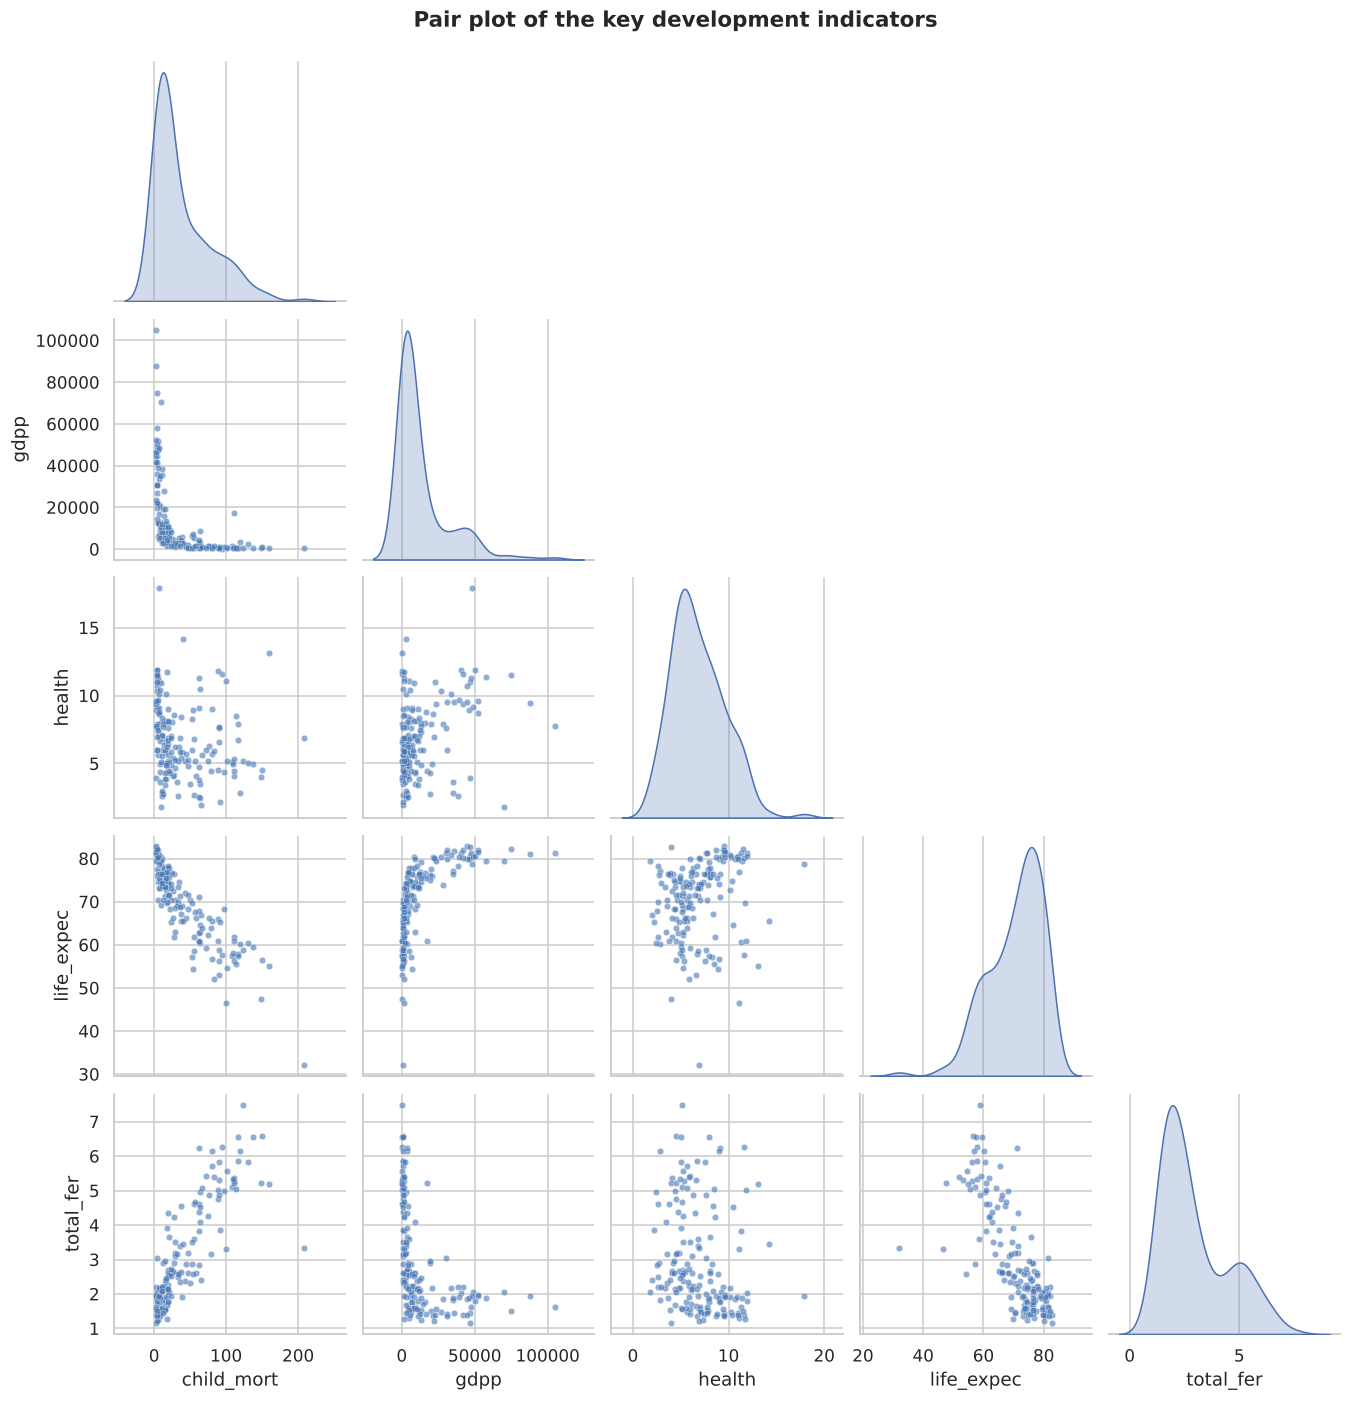

In [12]:
key = ["child_mort", "gdpp", "health", "life_expec", "total_fer"]
g = sns.pairplot(df_raw[key], corner=True, diag_kind="kde",
                 plot_kws={"s": 18, "alpha": 0.6, "color": "#4575b4"})
g.fig.suptitle("Pair plot of the key development indicators", y=1.02, fontsize=14, fontweight="bold")
plt.show()

### 4.5 Countries at the extremes

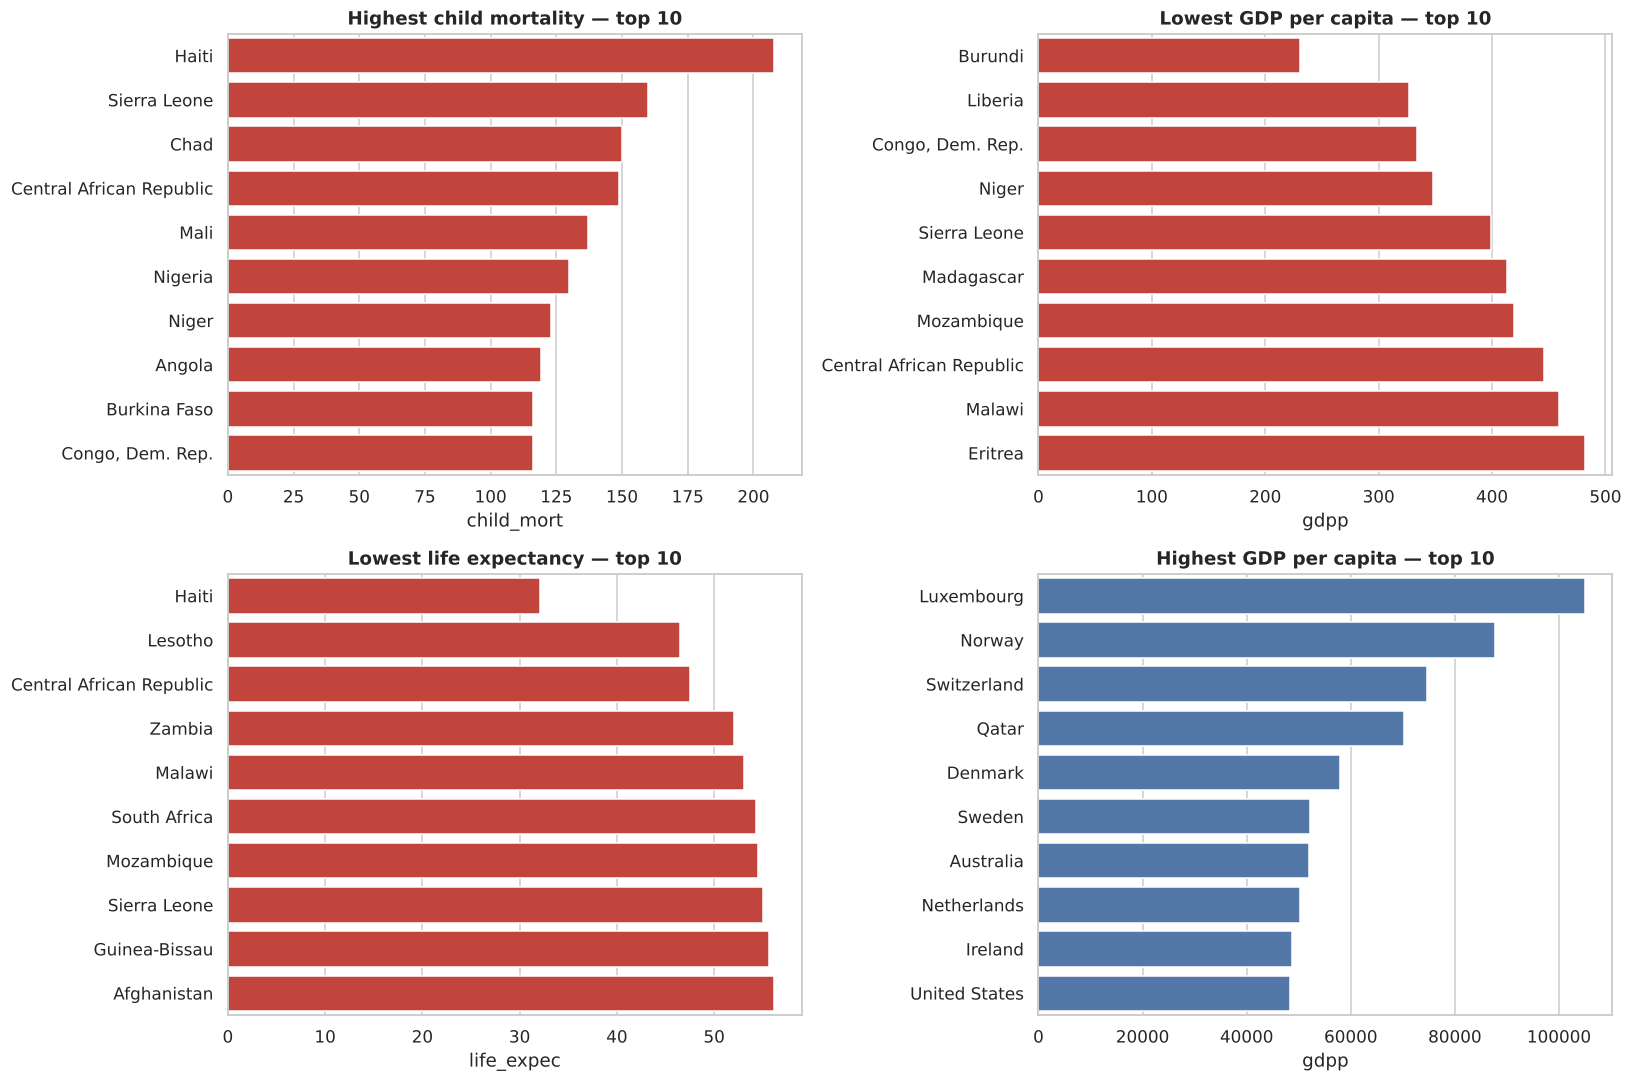

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
top = [("child_mort", False, "Highest child mortality"),
       ("gdpp", True, "Lowest GDP per capita"),
       ("life_expec", True, "Lowest life expectancy"),
       ("gdpp", False, "Highest GDP per capita")]
colors = ["#d73027", "#d73027", "#d73027", "#4575b4"]
for ax, (col, asc, title), c in zip(axes.ravel(), top, colors):
    s = df_raw.sort_values(col, ascending=asc).head(10)
    sns.barplot(data=s, x=col, y="country", ax=ax, color=c)
    ax.set_title(f"{title} — top 10")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 4.6 Key relationships

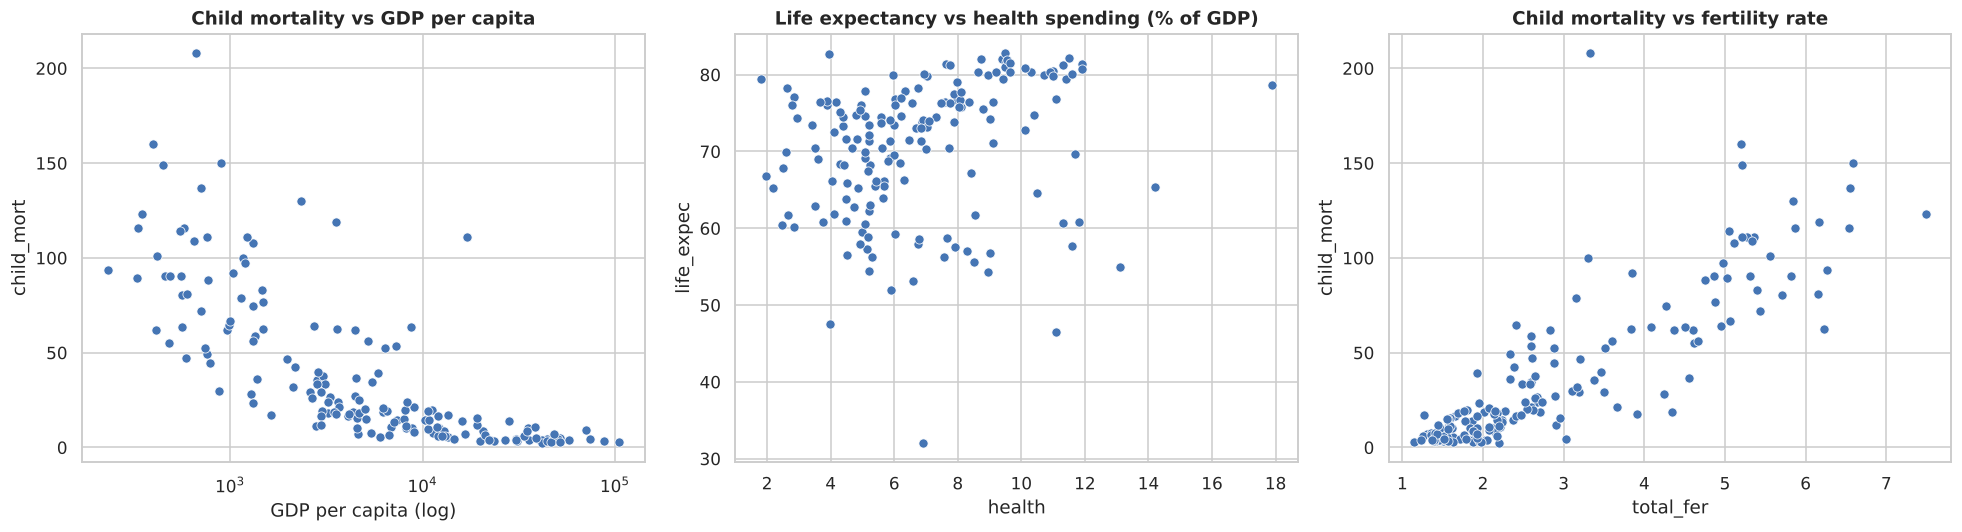

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=df_raw, x="gdpp", y="child_mort", ax=axes[0], color="#4575b4")
axes[0].set(xscale="log", title="Child mortality vs GDP per capita", xlabel="GDP per capita (log)")
sns.scatterplot(data=df_raw, x="health", y="life_expec", ax=axes[1], color="#4575b4")
axes[1].set(title="Life expectancy vs health spending (% of GDP)")
sns.scatterplot(data=df_raw, x="total_fer", y="child_mort", ax=axes[2], color="#4575b4")
axes[2].set(title="Child mortality vs fertility rate")
plt.tight_layout()
plt.show()

### 4.7 Factor analysis — latent factors behind the indicators
Factor analysis explains the 9 indicators with a small number of hidden factors plus noise. It is used here to understand the data. The clustering itself uses PCA (Step 5).

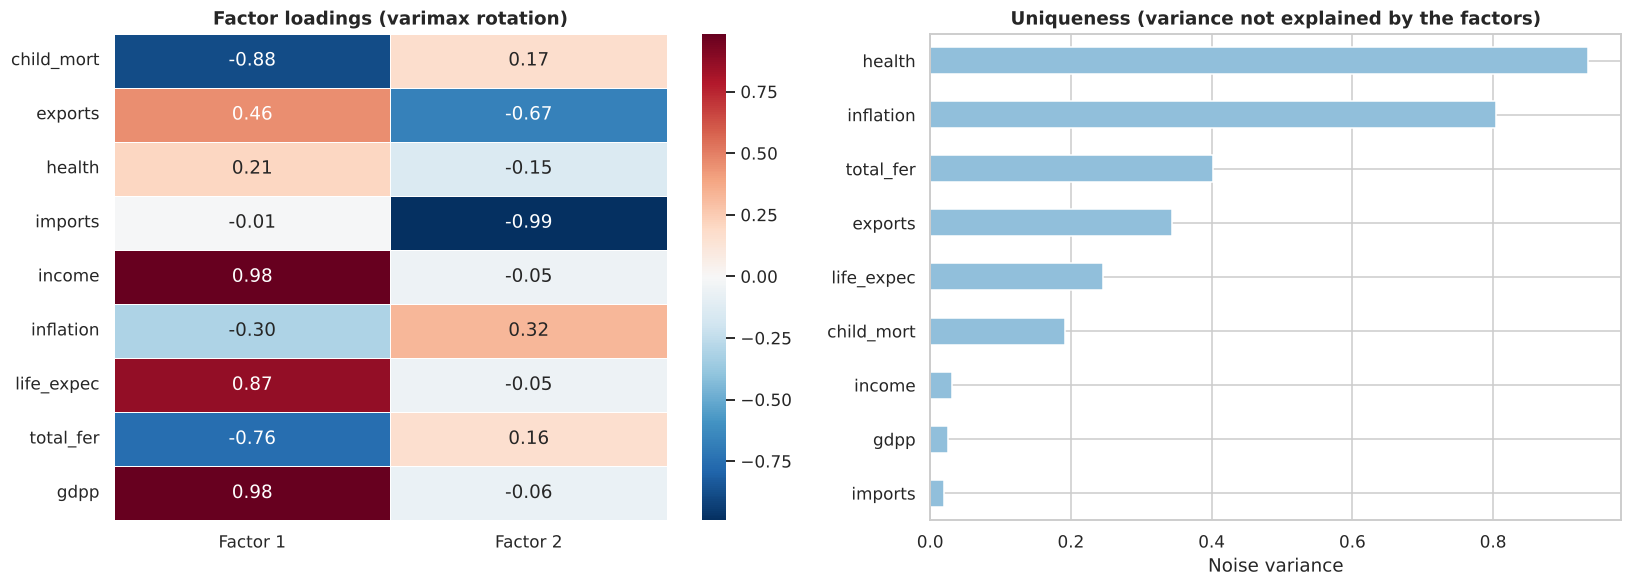

In [15]:
X_eda = PowerTransformer().fit_transform(df_raw[features])
fa = FactorAnalysis(n_components=2, rotation="varimax", random_state=RANDOM_STATE).fit(X_eda)
fa_load = pd.DataFrame(fa.components_.T, index=features, columns=["Factor 1", "Factor 2"])

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(fa_load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0], linewidths=0.5)
ax[0].set_title("Factor loadings (varimax rotation)")
pd.Series(fa.noise_variance_, index=features).sort_values().plot.barh(ax=ax[1], color="#91bfdb")
ax[1].set(title="Uniqueness (variance not explained by the factors)", xlabel="Noise variance")
plt.tight_layout()
plt.show()

One factor groups the human-development indicators (child mortality, life expectancy, fertility) and the other the economic ones (income, GDP, trade, health spending). `inflation` is mostly unique noise.

### 4.8 Measuring dissimilarity
Clustering depends on how distance between countries is measured. Below we compare Euclidean, Manhattan and cosine distance on the transformed data.

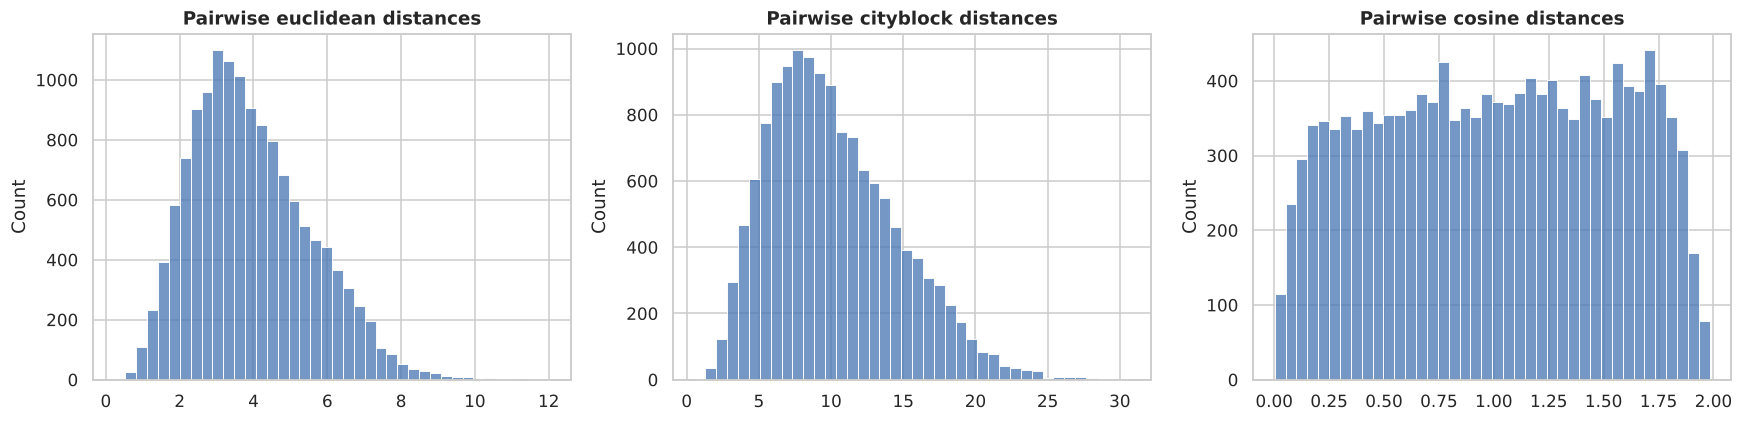

Rank correlation between the distance measures:
           euclidean  cityblock  cosine
euclidean      1.000      0.981   0.741
cityblock      0.981      1.000   0.761
cosine         0.741      0.761   1.000


In [16]:
D = {m: pdist(X_eda, metric=m) for m in ["euclidean", "cityblock", "cosine"]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (m, d) in zip(axes, D.items()):
    sns.histplot(d, bins=40, ax=ax, color="#4575b4", edgecolor="white")
    ax.set_title(f"Pairwise {m} distances")
plt.tight_layout()
plt.show()
print("Rank correlation between the distance measures:")
print(pd.DataFrame(D).corr(method="spearman").round(3))

Euclidean and Manhattan distances rank country pairs almost identically. Euclidean is used because Ward linkage requires it.

## Step 5 — Train–test split and pre-processing

In [17]:
df = df_raw.copy()
for col in ["exports", "health", "imports"]:
    df[col] = df[col] * df["gdpp"] / 100          # % of GDP  ->  USD per person

strata = pd.qcut(df["child_mort"], q=3, labels=["low", "mid", "high"])
train_df, test_df = train_test_split(df, test_size=0.20, random_state=RANDOM_STATE, stratify=strata)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)

print("Training set:", train_df.shape, "| Test set:", test_df.shape)
print("\nChild-mortality level in each set:")
print(pd.DataFrame({"train": pd.qcut(df["child_mort"], 3, labels=["low", "mid", "high"])[
                        df["country"].isin(train_df["country"])].value_counts(),
                    "test": pd.qcut(df["child_mort"], 3, labels=["low", "mid", "high"])[
                        df["country"].isin(test_df["country"])].value_counts()}))

Training set: (133, 10) | Test set: (34, 10)

Child-mortality level in each set:
            train  test
child_mort             
low            45    11
mid            44    11
high           44    12


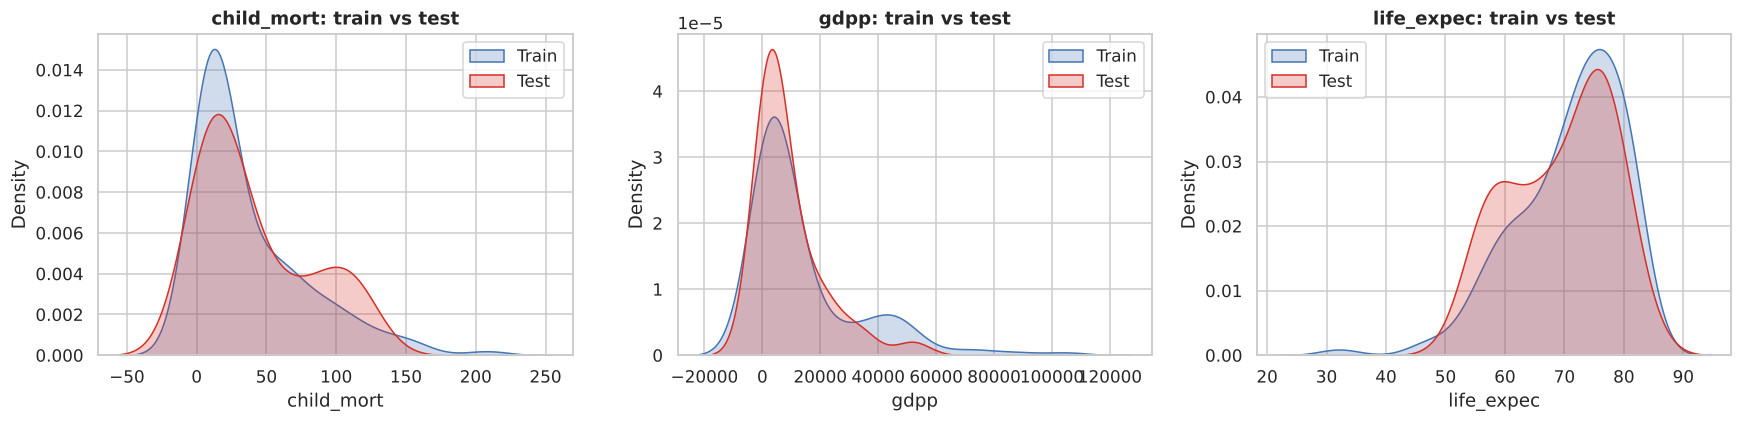

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["child_mort", "gdpp", "life_expec"]):
    sns.kdeplot(train_df[col], ax=ax, label="Train", fill=True, color="#4575b4")
    sns.kdeplot(test_df[col], ax=ax, label="Test", fill=True, color="#d73027")
    ax.set_title(f"{col}: train vs test")
    ax.legend()
plt.tight_layout()
plt.show()

### 5.1 Power transform + standardisation (fitted on train only)

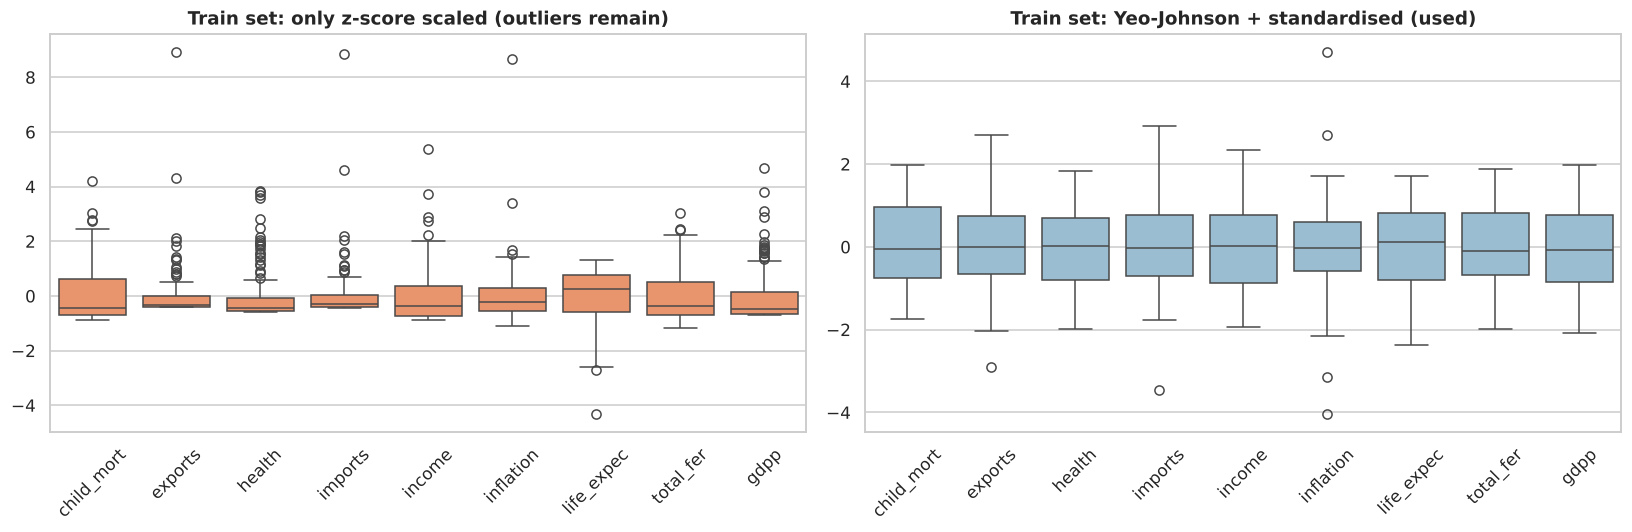

In [19]:
pt = PowerTransformer(method="yeo-johnson", standardize=True)
X_train_s = pt.fit_transform(train_df[features])
X_test_s = pt.transform(test_df[features])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(train_df[features]), columns=features),
            ax=axes[0], color="#fc8d59")
axes[0].set_title("Train set: only z-score scaled (outliers remain)")
sns.boxplot(data=pd.DataFrame(X_train_s, columns=features), ax=axes[1], color="#91bfdb")
axes[1].set_title("Train set: Yeo-Johnson + standardised (used)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 5.2 PCA and choosing the number of latent dimensions (fitted on train only)
We keep the smallest number of components that explains at least 95 % of the variance.

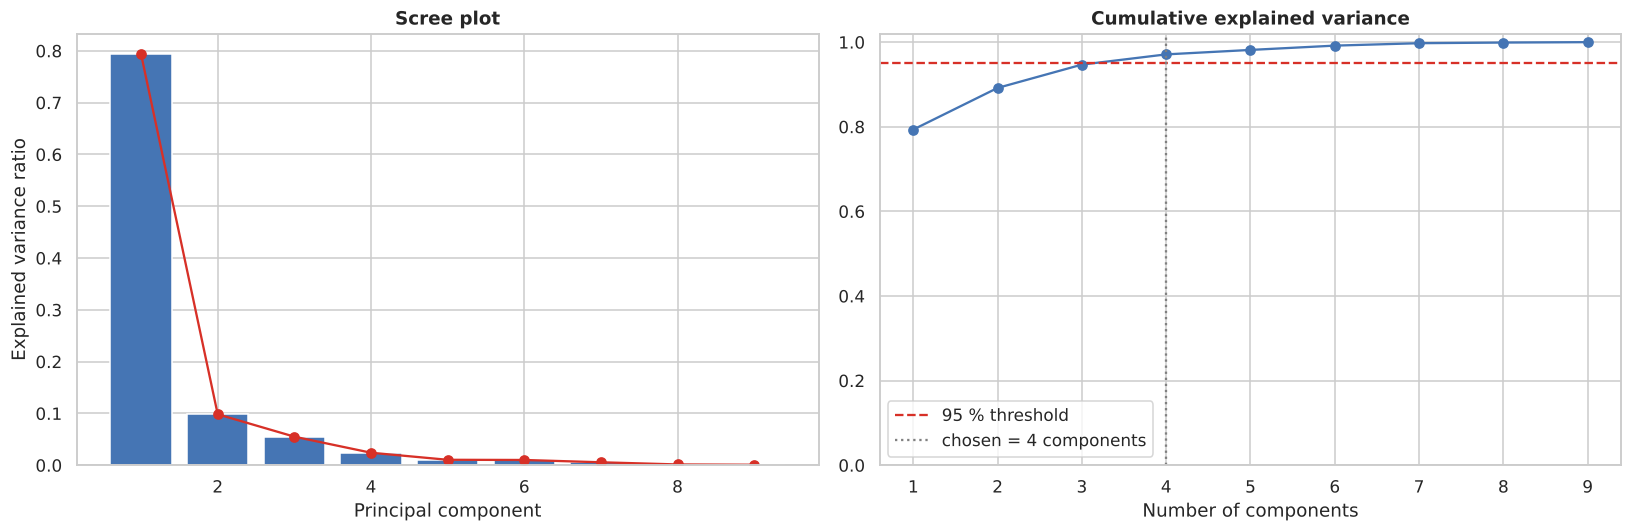

Components kept: 4  (97.1% of variance)
Eigenvalues: [7.195 0.892 0.5   0.219 0.095 0.092 0.052 0.014 0.009]


In [20]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n_comp = int(np.argmax(cum >= 0.95) + 1)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(range(1, len(evr) + 1), evr, color="#4575b4")
ax[0].plot(range(1, len(evr) + 1), evr, "o-", color="#d73027")
ax[0].set(title="Scree plot", xlabel="Principal component", ylabel="Explained variance ratio")
ax[1].plot(range(1, len(cum) + 1), cum, "o-", color="#4575b4")
ax[1].axhline(0.95, ls="--", color="#d73027", label="95 % threshold")
ax[1].axvline(n_comp, ls=":", color="grey", label=f"chosen = {n_comp} components")
ax[1].set(title="Cumulative explained variance", xlabel="Number of components", ylim=(0, 1.02))
ax[1].legend()
plt.tight_layout()
plt.show()
print(f"Components kept: {n_comp}  ({cum[n_comp-1]*100:.1f}% of variance)")
print("Eigenvalues:", pca_full.explained_variance_.round(3))

X_train: (133, 4) | X_test: (34, 4)


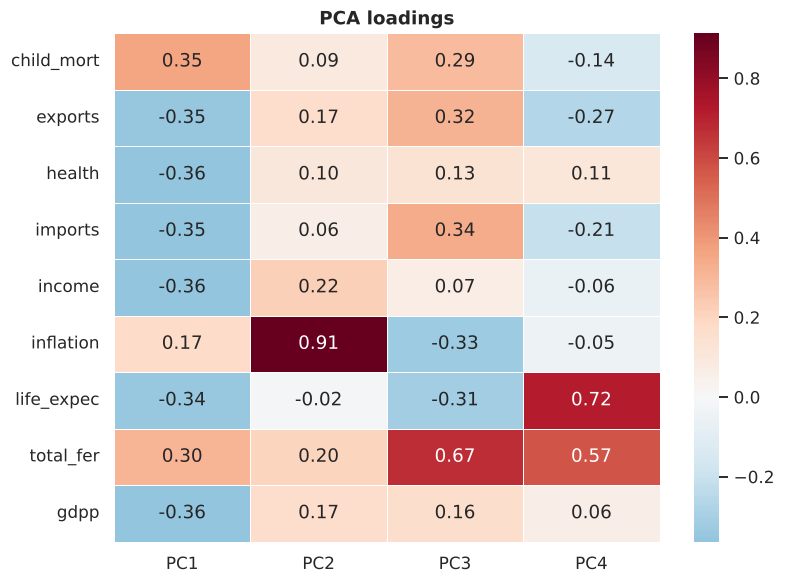

In [21]:
pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(X_train_s)
# Orient PC1 so that a HIGHER value means LOWER development
if np.corrcoef(pca.transform(X_train_s)[:, 0], train_df["child_mort"])[0, 1] < 0:
    pca.components_[0] *= -1

X_train = pca.transform(X_train_s)
X_test = pca.transform(X_test_s)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

loadings = pd.DataFrame(pca.components_.T, index=features,
                        columns=[f"PC{i+1}" for i in range(n_comp)])
plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("PCA loadings")
plt.show()

PC1 is an **under-development axis**: it rises with child mortality and fertility and falls with income, GDP, health spending and life expectancy.

## Step 6 — Train the models
A helper maps raw cluster numbers to development stages. The cluster with the highest median child mortality becomes Stage 1, so all three models use the same stage numbering.

In [22]:
STAGE_NAMES = {1: "Stage 1 – Least developed (aid priority)",
               2: "Stage 2 – Developing",
               3: "Stage 3 – Developed"}
STAGE_COLORS = {1: "#d73027", 2: "#fc8d59", 3: "#4575b4"}

def cluster_to_stage(cluster_ids, child_mort):
    # Return {cluster_id: stage} with stage 1 = highest median child mortality
    order = (pd.Series(np.asarray(child_mort)).groupby(np.asarray(cluster_ids)).median()
             .sort_values(ascending=False).index)
    return {c: i + 1 for i, c in enumerate(order)}

### 6.1 Model 1 (main): Agglomerative Hierarchical Clustering
#### Choosing the linkage method

In [23]:
methods = ["single", "complete", "average", "ward"]
links, rows = {}, []
d_train = pdist(X_train)
for m in methods:
    L = linkage(X_train, method=m, metric="euclidean")
    links[m] = L
    lab = fcluster(L, 3, criterion="maxclust")
    rows.append({"linkage": m,
                 "cophenetic_corr": round(cophenet(L, d_train)[0], 3),
                 "cluster_sizes_k3": sorted(np.bincount(lab)[1:].tolist(), reverse=True),
                 "silhouette_k3": round(silhouette_score(X_train, lab), 3)})
link_df = pd.DataFrame(rows).set_index("linkage")
link_df

,cophenetic_corr,cluster_sizes_k3,silhouette_k3
linkage,,,
single,0.350,"[131, 1, 1]",0.158
complete,0.664,"[50, 45, 38]",0.380
average,0.711,"[95, 37, 1]",0.426
ward,0.698,"[58, 38, 37]",0.421


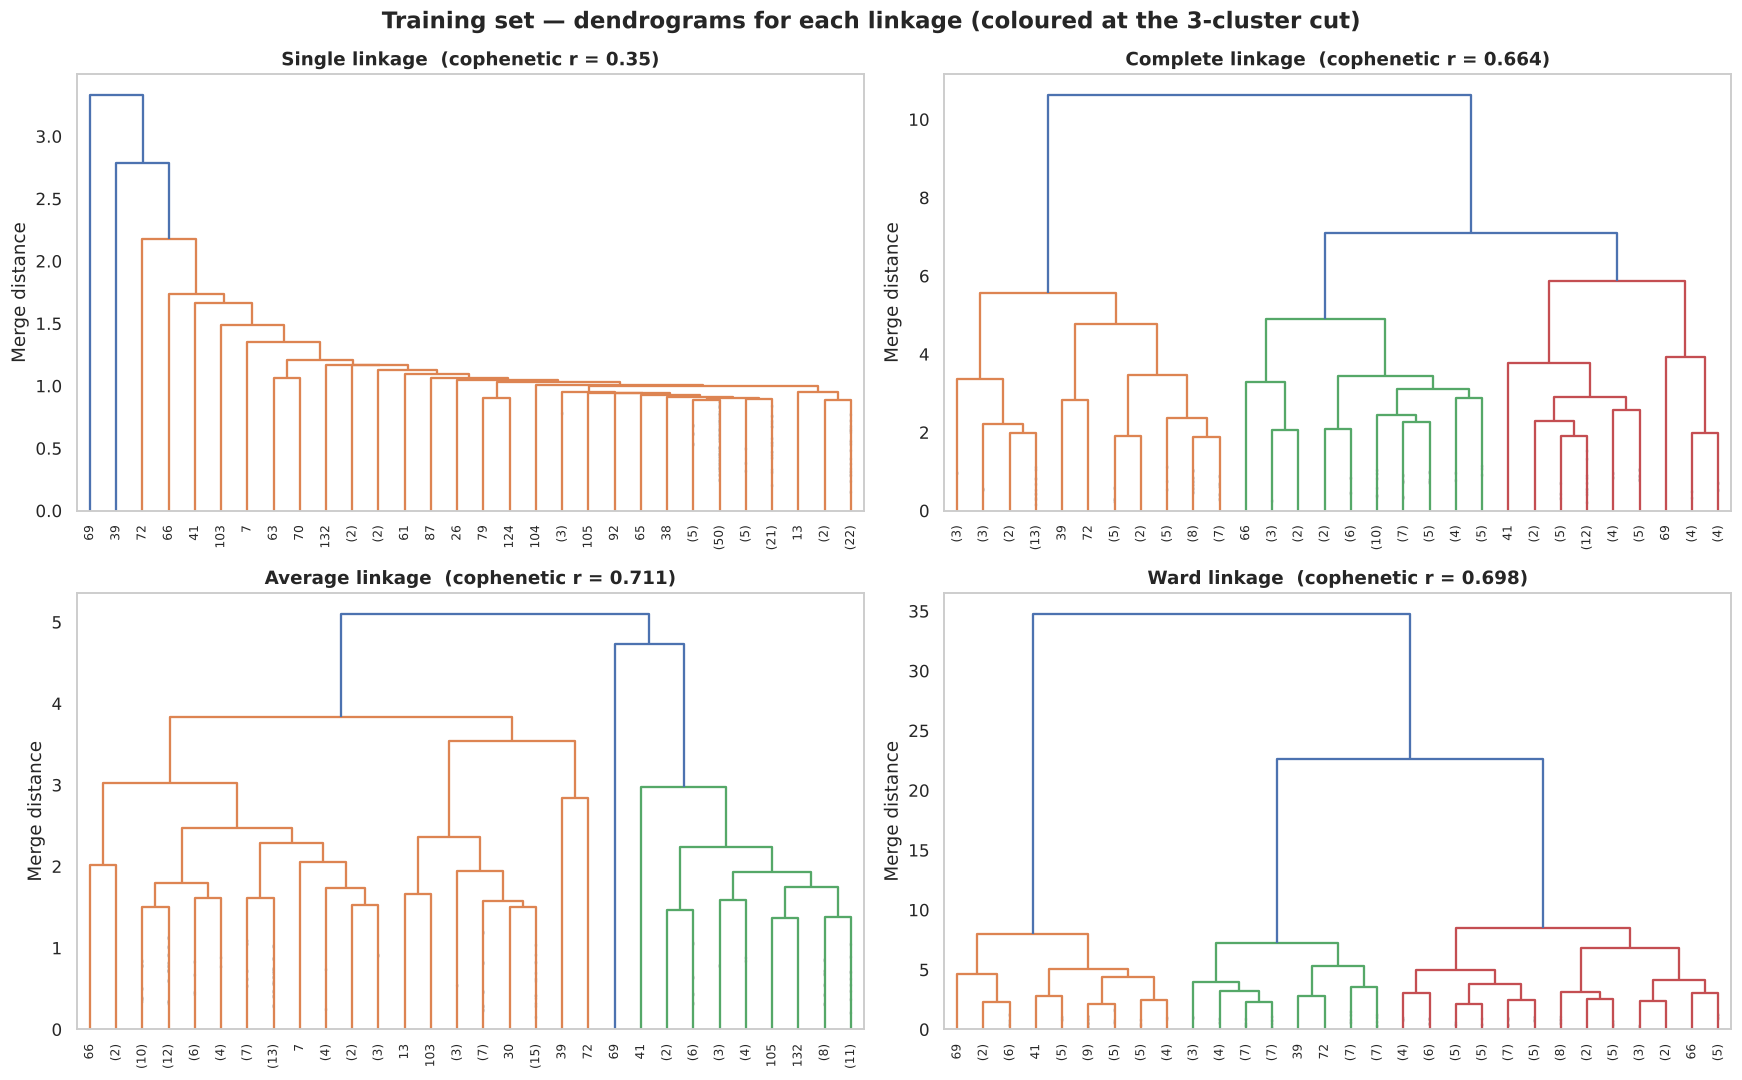

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, m in zip(axes.ravel(), methods):
    dendrogram(links[m], ax=ax, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=8,
               show_contracted=True, color_threshold=links[m][-2, 2] - 1e-9)
    ax.grid(False)
    ax.set_title(f"{m.capitalize()} linkage  (cophenetic r = {link_df.loc[m, 'cophenetic_corr']})")
    ax.set_ylabel("Merge distance")
fig.suptitle("Training set — dendrograms for each linkage (coloured at the 3-cluster cut)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Ward linkage is chosen.**
* **Single** linkage chains almost every country into one cluster, leaving two singletons.
* **Average** linkage has the highest cophenetic correlation, but it isolates one country as its own "stage".
* **Complete** linkage gives balanced groups, but its silhouette and cophenetic correlation are lower than Ward's.
* **Ward** gives compact, balanced groups with the best trade-off between silhouette and cophenetic correlation, which is what development stages should look like.

#### Choosing the number of clusters (stages)

In [25]:
L_train = links["ward"]
heights = L_train[:, 2][::-1]
ks = np.arange(2, 11)
rows = []
for k in ks:
    lab = fcluster(L_train, k, criterion="maxclust")
    rows.append({"k": k, "merge_gap": heights[k - 2] - heights[k - 1],
                 "silhouette": silhouette_score(X_train, lab),
                 "davies_bouldin": davies_bouldin_score(X_train, lab),
                 "calinski_harabasz": calinski_harabasz_score(X_train, lab)})
k_df = pd.DataFrame(rows).set_index("k").round(3)
k_df

,merge_gap,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,12.166,0.443,0.729,141.747
3,14.086,0.421,0.811,184.294
4,0.509,0.322,1.227,144.277
5,0.754,0.314,1.226,126.344
6,0.422,0.286,1.281,116.086
7,1.515,0.283,1.169,110.658
8,0.258,0.287,1.089,103.297
9,0.088,0.277,1.093,98.114
10,0.335,0.277,1.120,94.936


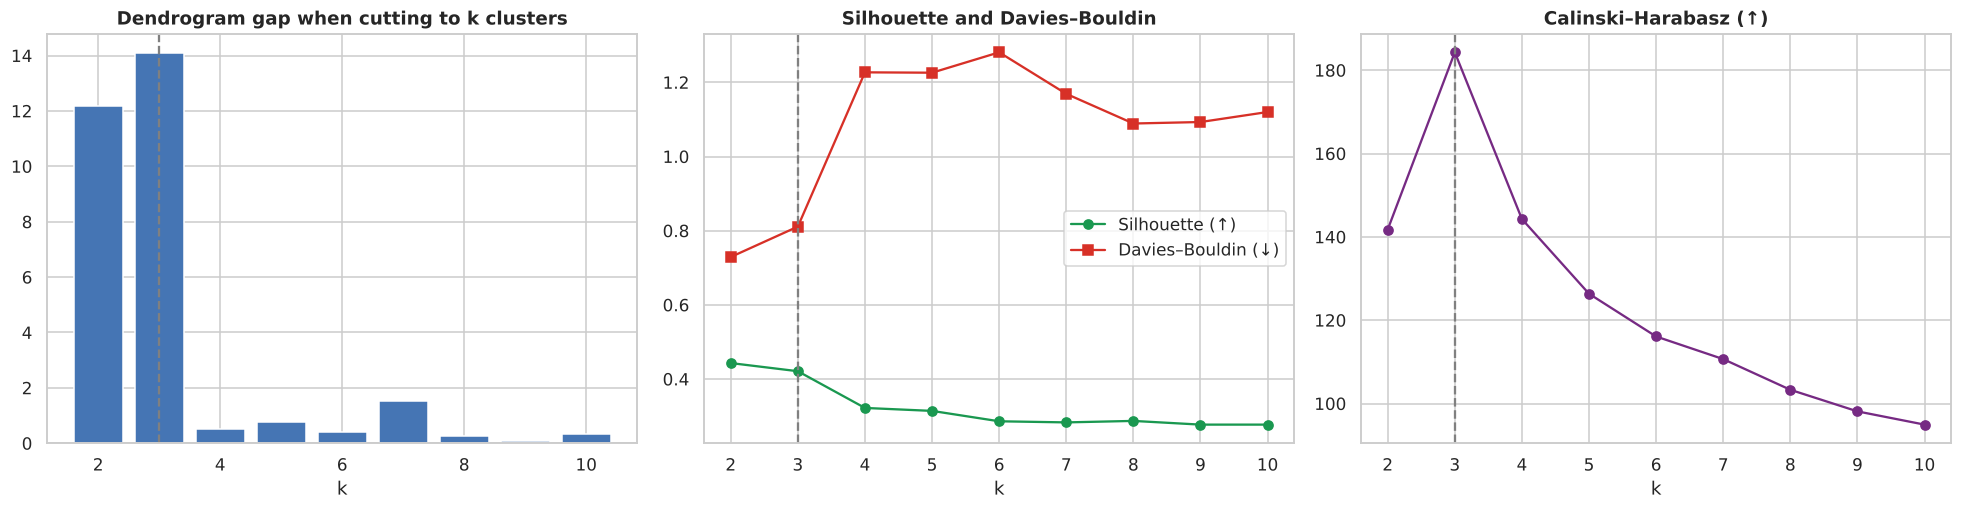

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].bar(k_df.index, k_df["merge_gap"], color="#4575b4")
axes[0].set(title="Dendrogram gap when cutting to k clusters", xlabel="k")
axes[1].plot(k_df.index, k_df["silhouette"], "o-", color="#1a9850", label="Silhouette (↑)")
axes[1].plot(k_df.index, k_df["davies_bouldin"], "s-", color="#d73027", label="Davies–Bouldin (↓)")
axes[1].set(title="Silhouette and Davies–Bouldin", xlabel="k"); axes[1].legend()
axes[2].plot(k_df.index, k_df["calinski_harabasz"], "o-", color="#762a83")
axes[2].set(title="Calinski–Harabasz (↑)", xlabel="k")
for ax in axes:
    ax.axvline(3, ls="--", color="grey")
plt.tight_layout()
plt.show()

**k = 3 is chosen.** k = 2 only separates rich from poor, which is too coarse for aid targeting. Among k ≥ 3, k = 3 has the largest dendrogram gap and good Davies–Bouldin and Calinski–Harabasz scores.

#### Training the hierarchical model

In [27]:
K = 3
hc = AgglomerativeClustering(n_clusters=K, linkage="ward", metric="euclidean")
hc_train_clusters = hc.fit_predict(X_train)

hc_map = cluster_to_stage(hc_train_clusters, train_df["child_mort"])
hc_train = pd.Series(hc_train_clusters).map(hc_map).values

# Agglomerative clustering has no built-in predict(), so we store each stage's
# centroid; a new country is assigned to the nearest centroid (consistent with Ward,
# which minimises within-cluster variance).
hc_centroids = pd.DataFrame(X_train).groupby(hc_train).mean()

def hc_predict(X):
    dist = ((X[:, None, :] - hc_centroids.values[None, :, :]) ** 2).sum(axis=2)
    return hc_centroids.index.values[dist.argmin(axis=1)]

print("Hierarchical model trained. Countries per stage (train):")
print(pd.Series(hc_train).map(STAGE_NAMES).value_counts().sort_index())

Hierarchical model trained. Countries per stage (train):
Stage 1 – Least developed (aid priority)    38
Stage 2 – Developing                        58
Stage 3 – Developed                         37
Name: count, dtype: int64


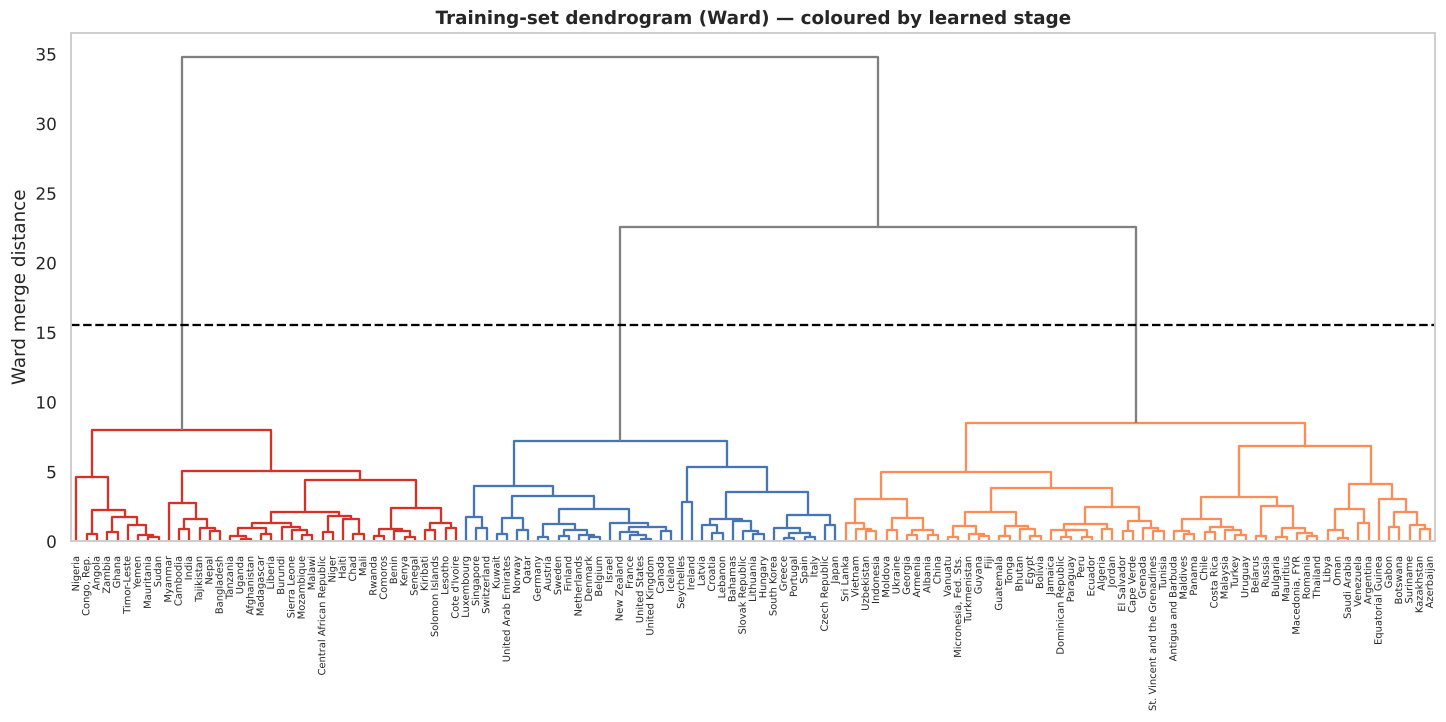

In [28]:
# Training-set dendrogram
n_tr = len(train_df)
node_stage = {i: hc_train[i] for i in range(n_tr)}
for j, (a, b, _, _) in enumerate(L_train):
    sa, sb = node_stage[int(a)], node_stage[int(b)]
    node_stage[n_tr + j] = sa if sa == sb else None
train_link_color = lambda n: STAGE_COLORS.get(node_stage[n], "grey")

fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(L_train, labels=train_df["country"].values, leaf_rotation=90, leaf_font_size=6.5,
           link_color_func=train_link_color, ax=ax)
ax.grid(False)
ax.axhline((heights[1] + heights[2]) / 2, ls="--", color="black")
ax.set(title="Training-set dendrogram (Ward) — coloured by learned stage", ylabel="Ward merge distance")
plt.show()

### 6.2 Model 2: K-means clustering
The elbow method (inertia) and silhouette are used to check k.

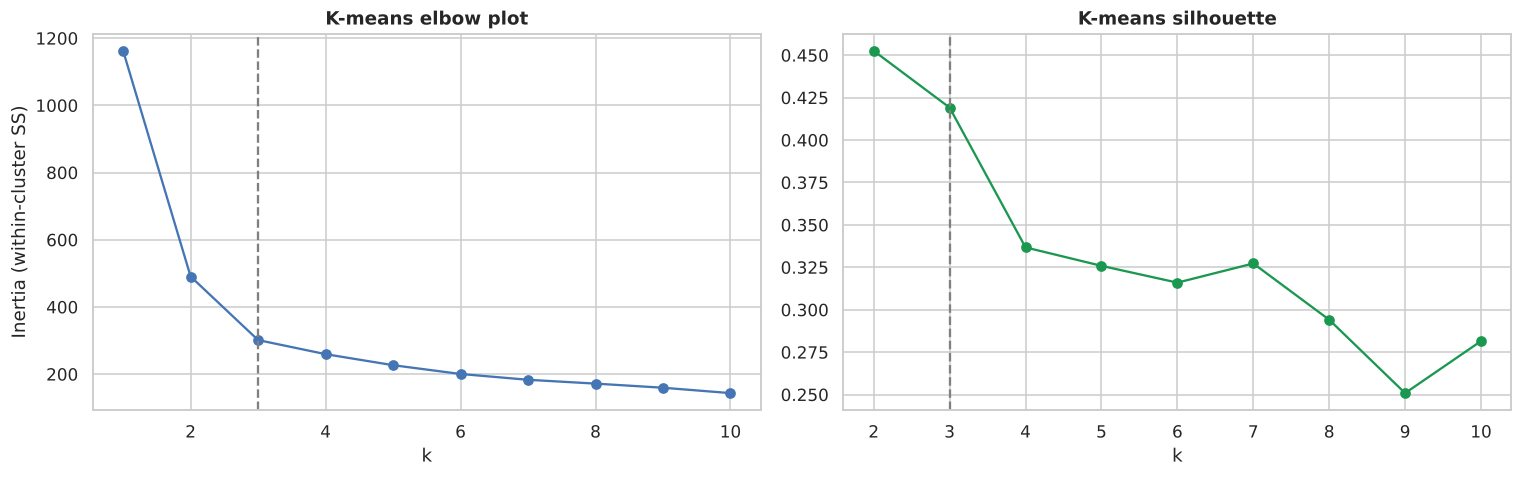

K-means trained. Countries per stage (train):
Stage 1 – Least developed (aid priority)    40
Stage 2 – Developing                        55
Stage 3 – Developed                         38
Name: count, dtype: int64


In [29]:
inertia, sil_km = [], []
for k in range(1, 11):
    m = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_train)
    inertia.append(m.inertia_)
    sil_km.append(silhouette_score(X_train, m.labels_) if k > 1 else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, 11), inertia, "o-", color="#4575b4")
axes[0].set(title="K-means elbow plot", xlabel="k", ylabel="Inertia (within-cluster SS)")
axes[1].plot(range(1, 11), sil_km, "o-", color="#1a9850")
axes[1].set(title="K-means silhouette", xlabel="k")
for ax in axes:
    ax.axvline(3, ls="--", color="grey")
plt.tight_layout()
plt.show()

km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X_train)
km_map = cluster_to_stage(km.labels_, train_df["child_mort"])
km_train = pd.Series(km.labels_).map(km_map).values
print("K-means trained. Countries per stage (train):")
print(pd.Series(km_train).map(STAGE_NAMES).value_counts().sort_index())

### 6.3 Model 3: Gaussian Mixture Model (fitted with the EM algorithm)
* **E-step:** compute each country's probability of belonging to each Gaussian.
* **M-step:** update the means, covariances and mixing weights using those probabilities.
* Repeat until the log-likelihood stops improving.

BIC and AIC are used to check the number of components.

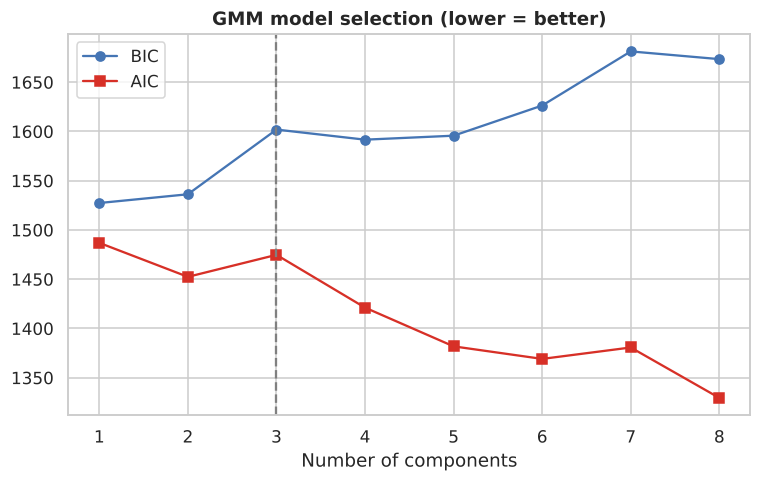

GMM trained. EM converged: True in 4 iterations
Countries per stage (train):
Stage 1 – Least developed (aid priority)    38
Stage 2 – Developing                        56
Stage 3 – Developed                         39
Name: count, dtype: int64


In [30]:
bic, aic = [], []
for k in range(1, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=5,
                        random_state=RANDOM_STATE).fit(X_train)
    bic.append(g.bic(X_train)); aic.append(g.aic(X_train))

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, 9), bic, "o-", label="BIC", color="#4575b4")
plt.plot(range(1, 9), aic, "s-", label="AIC", color="#d73027")
plt.axvline(3, ls="--", color="grey")
plt.title("GMM model selection (lower = better)"); plt.xlabel("Number of components"); plt.legend()
plt.show()

gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=10,
                      random_state=RANDOM_STATE).fit(X_train)
gmm_map = cluster_to_stage(gmm.predict(X_train), train_df["child_mort"])
gmm_train = pd.Series(gmm.predict(X_train)).map(gmm_map).values
print(f"GMM trained. EM converged: {gmm.converged_} in {gmm.n_iter_} iterations")
print("Countries per stage (train):")
print(pd.Series(gmm_train).map(STAGE_NAMES).value_counts().sort_index())

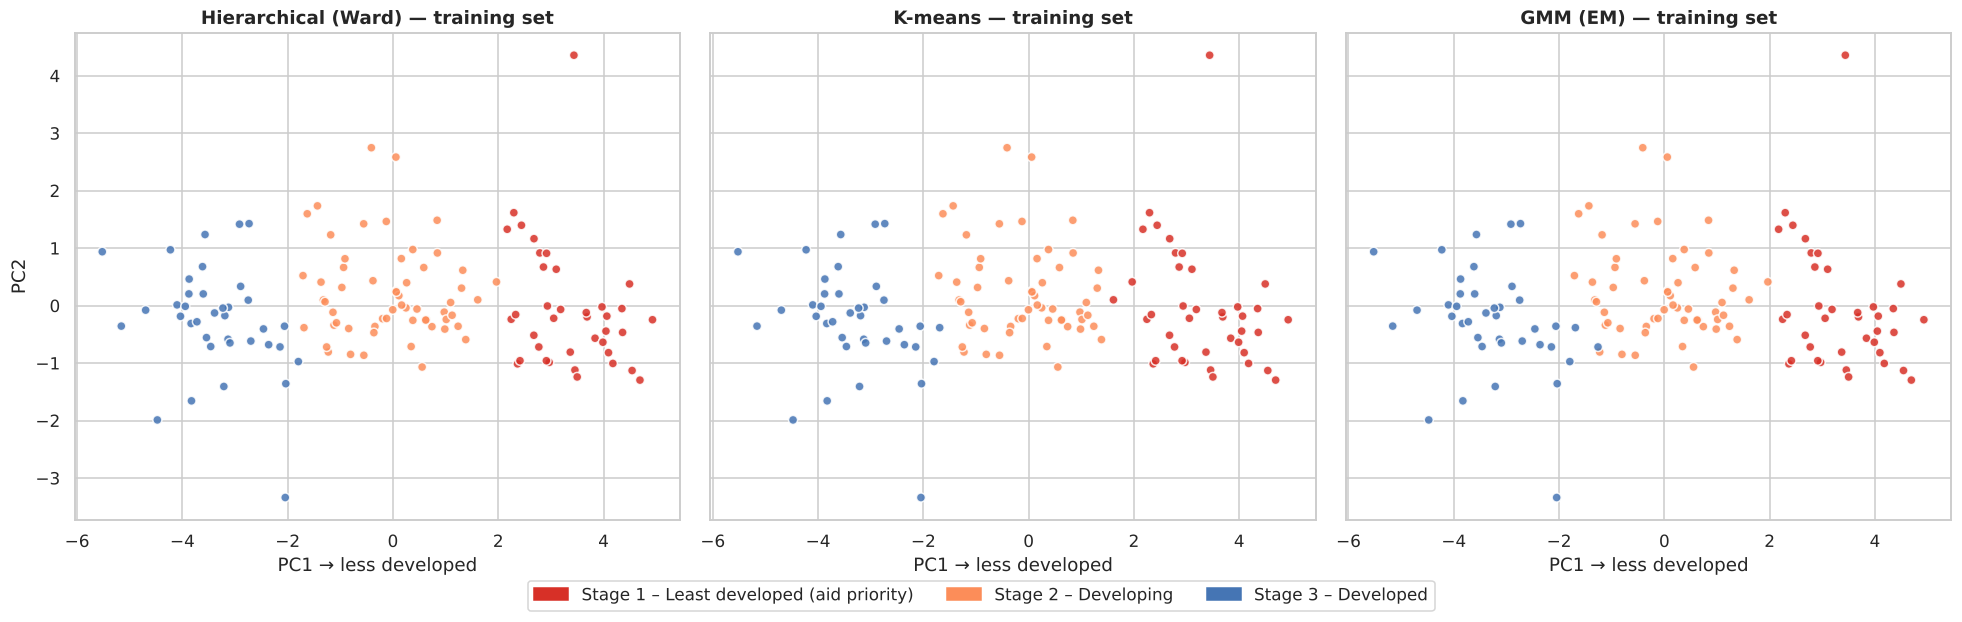

In [31]:
# Learned clusters on the training set, side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for ax, lab, name in zip(axes, [hc_train, km_train, gmm_train],
                         ["Hierarchical (Ward)", "K-means", "GMM (EM)"]):
    ax.scatter(X_train[:, 0], X_train[:, 1], c=pd.Series(lab).map(STAGE_COLORS),
               s=35, alpha=0.85, edgecolor="white")
    ax.set(title=f"{name} — training set", xlabel="PC1 → less developed")
axes[0].set_ylabel("PC2")
fig.legend(handles=[Patch(color=STAGE_COLORS[s], label=STAGE_NAMES[s]) for s in STAGE_NAMES],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()

## Step 7 — Predict development stages for the test countries
The 34 test countries were never seen during training. Each model assigns them to a stage:
* **Hierarchical:** nearest stage centroid learned from the training dendrogram
* **K-means:** `km.predict()` (nearest K-means centre)
* **GMM:** `gmm.predict()` (most probable Gaussian) and `gmm.predict_proba()` (confidence)

In [32]:
hc_pred = hc_predict(X_test)
km_pred = pd.Series(km.predict(X_test)).map(km_map).values
gmm_pred = pd.Series(gmm.predict(X_test)).map(gmm_map).values
gmm_conf = gmm.predict_proba(X_test).max(axis=1)

pred_df = pd.DataFrame({
    "country": test_df["country"],
    "child_mort": test_df["child_mort"],
    "gdpp": test_df["gdpp"],
    "life_expec": test_df["life_expec"],
    "Hierarchical_pred": hc_pred,
    "KMeans_pred": km_pred,
    "GMM_pred": gmm_pred,
    "GMM_confidence": gmm_conf.round(3),
}).sort_values("child_mort", ascending=False).reset_index(drop=True)
pred_df

,country,child_mort,gdpp,life_expec,Hierarchical_pred,KMeans_pred,GMM_pred,GMM_confidence
0,"Congo, Dem. Rep.",116.0,334,57.5,1,1,1,1.000
1,Burkina Faso,116.0,575,57.9,1,1,1,1.000
2,Guinea-Bissau,114.0,547,55.6,1,1,1,1.000
3,Guinea,109.0,648,58.0,1,1,1,0.999
4,Cameroon,108.0,1310,57.3,1,1,1,0.995
5,Pakistan,92.1,1040,65.3,1,1,1,0.995
6,Togo,90.3,488,58.7,1,1,1,0.999
7,Gambia,80.3,562,65.5,1,1,1,0.999
8,Lao,78.9,1140,63.8,1,1,1,0.890
9,Namibia,56.0,5190,58.6,2,2,2,0.936


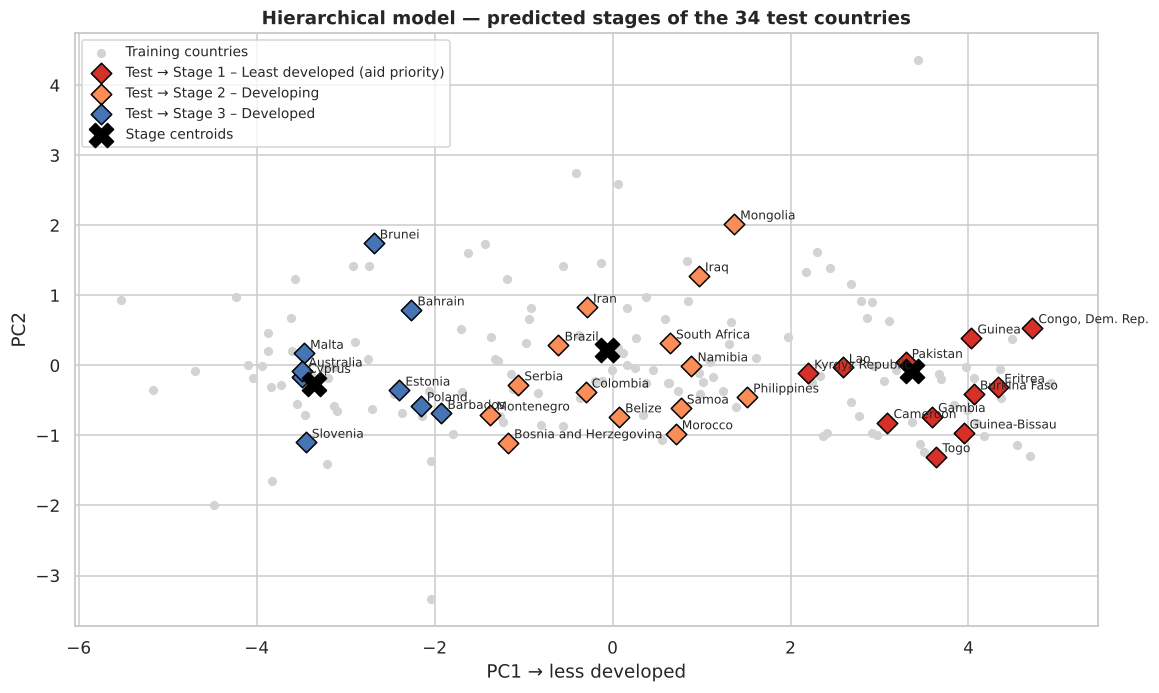

In [33]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(X_train[:, 0], X_train[:, 1], c="lightgrey", s=25, label="Training countries")
for s in STAGE_NAMES:
    m = hc_pred == s
    ax.scatter(X_test[m, 0], X_test[m, 1], c=STAGE_COLORS[s], s=90, edgecolor="black",
               marker="D", label=f"Test → {STAGE_NAMES[s]}")
ax.scatter(hc_centroids[0], hc_centroids[1], c="black", marker="X", s=250, label="Stage centroids")
for i, c in enumerate(test_df["country"]):
    ax.annotate(c, (X_test[i, 0], X_test[i, 1]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set(title="Hierarchical model — predicted stages of the 34 test countries",
       xlabel="PC1 → less developed", ylabel="PC2")
ax.legend(fontsize=9)
plt.show()

## Step 8 — Accuracy and evaluation

Clustering is **unsupervised**: the dataset has no "correct stage" column. Accuracy is therefore measured in two ways.

1. **Prediction accuracy (generalisation).** Each model is also fitted on all 167 countries; that grouping is the reference. If a model trained on only 80 % of the countries puts the unseen 20 % into the same stage as the full model, it has learned a stable structure. We report accuracy, a confusion matrix and precision / recall / F1.
2. **Internal cluster quality.** Silhouette (↑), Davies–Bouldin (↓) and Calinski–Harabasz (↑) measure how compact and well-separated the clusters are, without needing labels.

In [34]:
# Reference labels: each algorithm fitted on ALL 167 countries (same transform)
X_all = pca.transform(pt.transform(df[features]))
test_idx = df.index[df["country"].isin(test_df["country"])]
test_pos = [df.index[df["country"] == c][0] for c in test_df["country"]]
train_pos = [df.index[df["country"] == c][0] for c in train_df["country"]]

ref_hc_raw = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_all)
ref_hc = pd.Series(ref_hc_raw).map(cluster_to_stage(ref_hc_raw, df["child_mort"])).values

ref_km_model = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X_all)
ref_km = pd.Series(ref_km_model.labels_).map(cluster_to_stage(ref_km_model.labels_, df["child_mort"])).values

ref_gmm_model = GaussianMixture(n_components=K, covariance_type="full", n_init=10,
                                random_state=RANDOM_STATE).fit(X_all)
ref_gmm_raw = ref_gmm_model.predict(X_all)
ref_gmm = pd.Series(ref_gmm_raw).map(cluster_to_stage(ref_gmm_raw, df["child_mort"])).values

models = {
    "Hierarchical (Ward)": (hc_train, hc_pred, ref_hc),
    "K-means":             (km_train, km_pred, ref_km),
    "GMM (EM)":            (gmm_train, gmm_pred, ref_gmm),
}

rows = []
for name, (tr, te, ref) in models.items():
    rows.append({
        "Model": name,
        "Train accuracy": accuracy_score(ref[train_pos], tr),
        "Test accuracy": accuracy_score(ref[test_pos], te),
        "Test silhouette": silhouette_score(X_test, te),
        "Train silhouette": silhouette_score(X_train, tr),
        "Train Davies-Bouldin": davies_bouldin_score(X_train, tr),
        "Train Calinski-Harabasz": calinski_harabasz_score(X_train, tr),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Train accuracy,Test accuracy,Test silhouette,Train silhouette,Train Davies-Bouldin,Train Calinski-Harabasz
Model,,,,,,
Hierarchical (Ward),0.857,0.912,0.42,0.421,0.811,184.294
K-means,0.992,1.000,0.42,0.419,0.825,185.699
GMM (EM),0.992,0.971,0.42,0.416,0.826,183.000


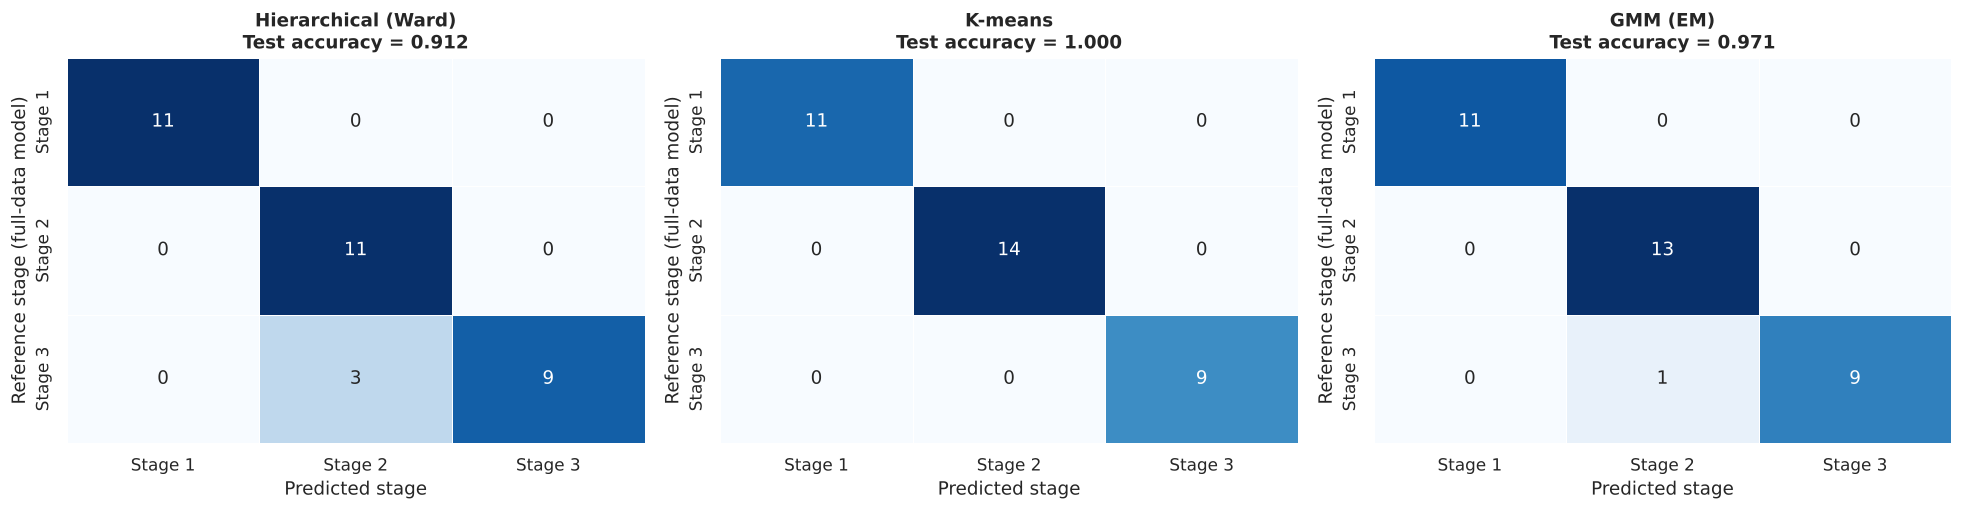

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
labels_txt = ["Stage 1", "Stage 2", "Stage 3"]
for ax, (name, (tr, te, ref)) in zip(axes, models.items()):
    cm = confusion_matrix(ref[test_pos], te, labels=[1, 2, 3])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels_txt, yticklabels=labels_txt, linewidths=0.5)
    ax.set(title=f"{name}\nTest accuracy = {accuracy_score(ref[test_pos], te):.3f}",
           xlabel="Predicted stage", ylabel="Reference stage (full-data model)")
plt.tight_layout()
plt.show()

In [36]:
print("Classification report — Hierarchical (Ward), test set\n")
print(classification_report(ref_hc[test_pos], hc_pred, labels=[1, 2, 3],
                            target_names=[STAGE_NAMES[s] for s in [1, 2, 3]], zero_division=0))

Classification report — Hierarchical (Ward), test set

                                          precision    recall  f1-score   support

Stage 1 – Least developed (aid priority)       1.00      1.00      1.00        11
                    Stage 2 – Developing       0.79      1.00      0.88        11
                     Stage 3 – Developed       1.00      0.75      0.86        12

                                accuracy                           0.91        34
                               macro avg       0.93      0.92      0.91        34
                            weighted avg       0.93      0.91      0.91        34



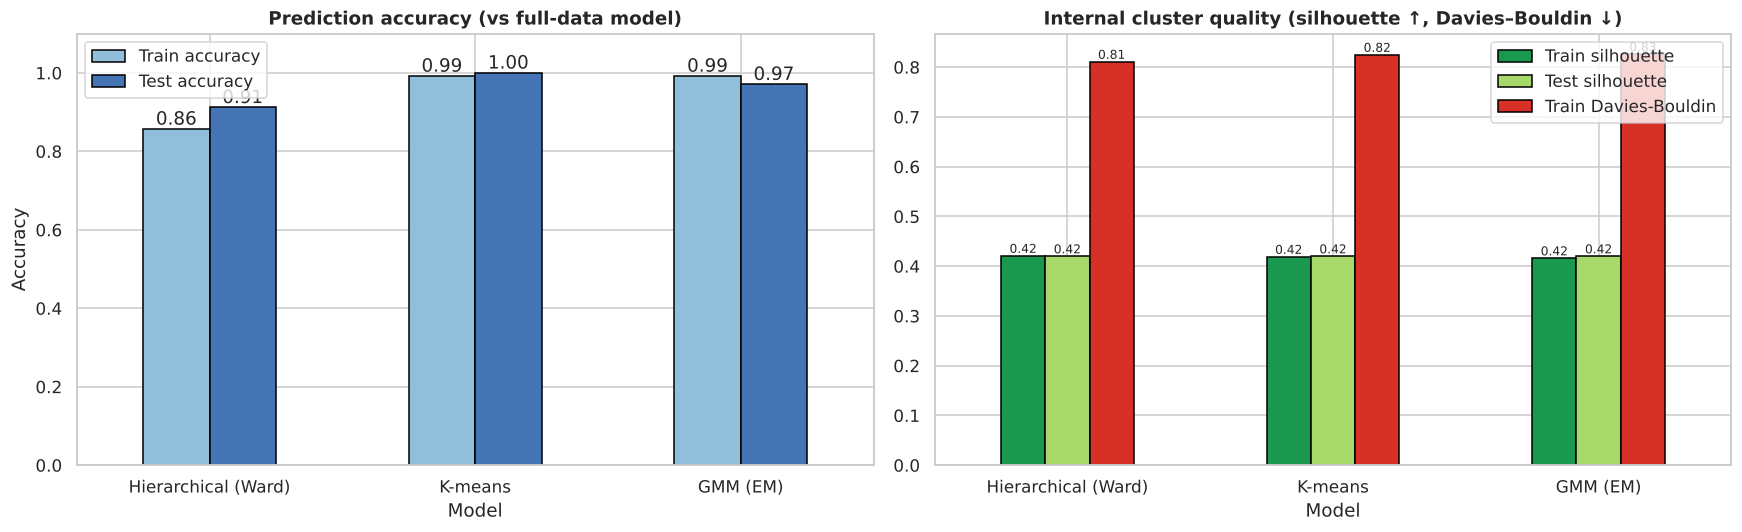

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
results[["Train accuracy", "Test accuracy"]].plot.bar(ax=axes[0], color=["#91bfdb", "#4575b4"],
                                                       edgecolor="black", rot=0)
axes[0].set(title="Prediction accuracy (vs full-data model)", ylim=(0, 1.1), ylabel="Accuracy")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f")
results[["Train silhouette", "Test silhouette", "Train Davies-Bouldin"]].plot.bar(
    ax=axes[1], color=["#1a9850", "#a6d96a", "#d73027"], edgecolor="black", rot=0)
axes[1].set(title="Internal cluster quality (silhouette ↑, Davies–Bouldin ↓)")
for c in axes[1].containers:
    axes[1].bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

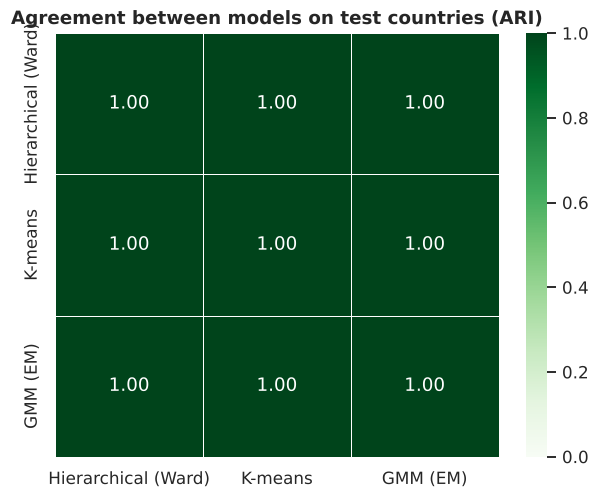

In [38]:
# How much do the three models agree with each other on the test countries?
agree = pd.DataFrame(index=models, columns=models, dtype=float)
preds = {n: v[1] for n, v in models.items()}
for a in models:
    for b in models:
        agree.loc[a, b] = adjusted_rand_score(preds[a], preds[b])
plt.figure(figsize=(6.5, 5))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, linewidths=0.5)
plt.title("Agreement between models on test countries (ARI)")
plt.show()

In [39]:
# Which test countries did the hierarchical model place in a different stage?
wrong = pd.DataFrame({"country": test_df["country"], "reference_stage": ref_hc[test_pos],
                      "predicted_stage": hc_pred, "child_mort": test_df["child_mort"],
                      "gdpp": test_df["gdpp"]})
wrong[wrong["reference_stage"] != wrong["predicted_stage"]]

,country,reference_stage,predicted_stage,child_mort,gdpp
13,Bosnia and Herzegovina,3,2,6.9,4610
15,Serbia,3,2,7.6,5410
33,Montenegro,3,2,6.8,6680


### Interpreting the results
* **All three models find almost the same structure.** Training silhouette is about 0.42 for every model, and the agreement heatmap shows the models largely agree on the test countries.
* **Hierarchical clustering has the best internal quality on the training set** (highest silhouette, lowest Davies–Bouldin), with K-means and GMM very close behind.
* **K-means and GMM have higher prediction accuracy.** Their centres move very little when 20 % of countries are removed. Ward merging is greedy: one early merge can shift a few borderline countries into a neighbouring stage. The misclassified countries listed above all sit on the boundary between two stages; none are confused between Stage 1 and Stage 3.
* **Stage 1, the aid-priority group, is predicted perfectly by all three models.** For aid allocation, this is the stage that matters most.

**Final model: Agglomerative Hierarchical Clustering (Ward).** It is the only model that produces the dendrogram required by the problem statement. It needs no random initialisation, gives the best internal cluster quality, and its tree shows how far apart the stages are and which sub-groups exist inside each stage. K-means and GMM confirm that the three stages are a stable, real structure.

## Step 9 — Final model graphs
The final hierarchical model is fitted on all 167 countries (same pre-processing and PCA) to produce the complete dendrogram and development-stage map.

In [40]:
L_final = linkage(X_all, method="ward")
final_stage = ref_hc
df_raw["stage_id"] = final_stage
df_raw["stage"] = pd.Series(final_stage).map(STAGE_NAMES).values
h_all = L_final[:, 2][::-1]
cut = (h_all[K - 2] + h_all[K - 1]) / 2
print(df_raw["stage"].value_counts().sort_index())

stage
Stage 1 – Least developed (aid priority)    46
Stage 2 – Developing                        56
Stage 3 – Developed                         65
Name: count, dtype: int64


### 9.1 Final dendrogram — all 167 countries

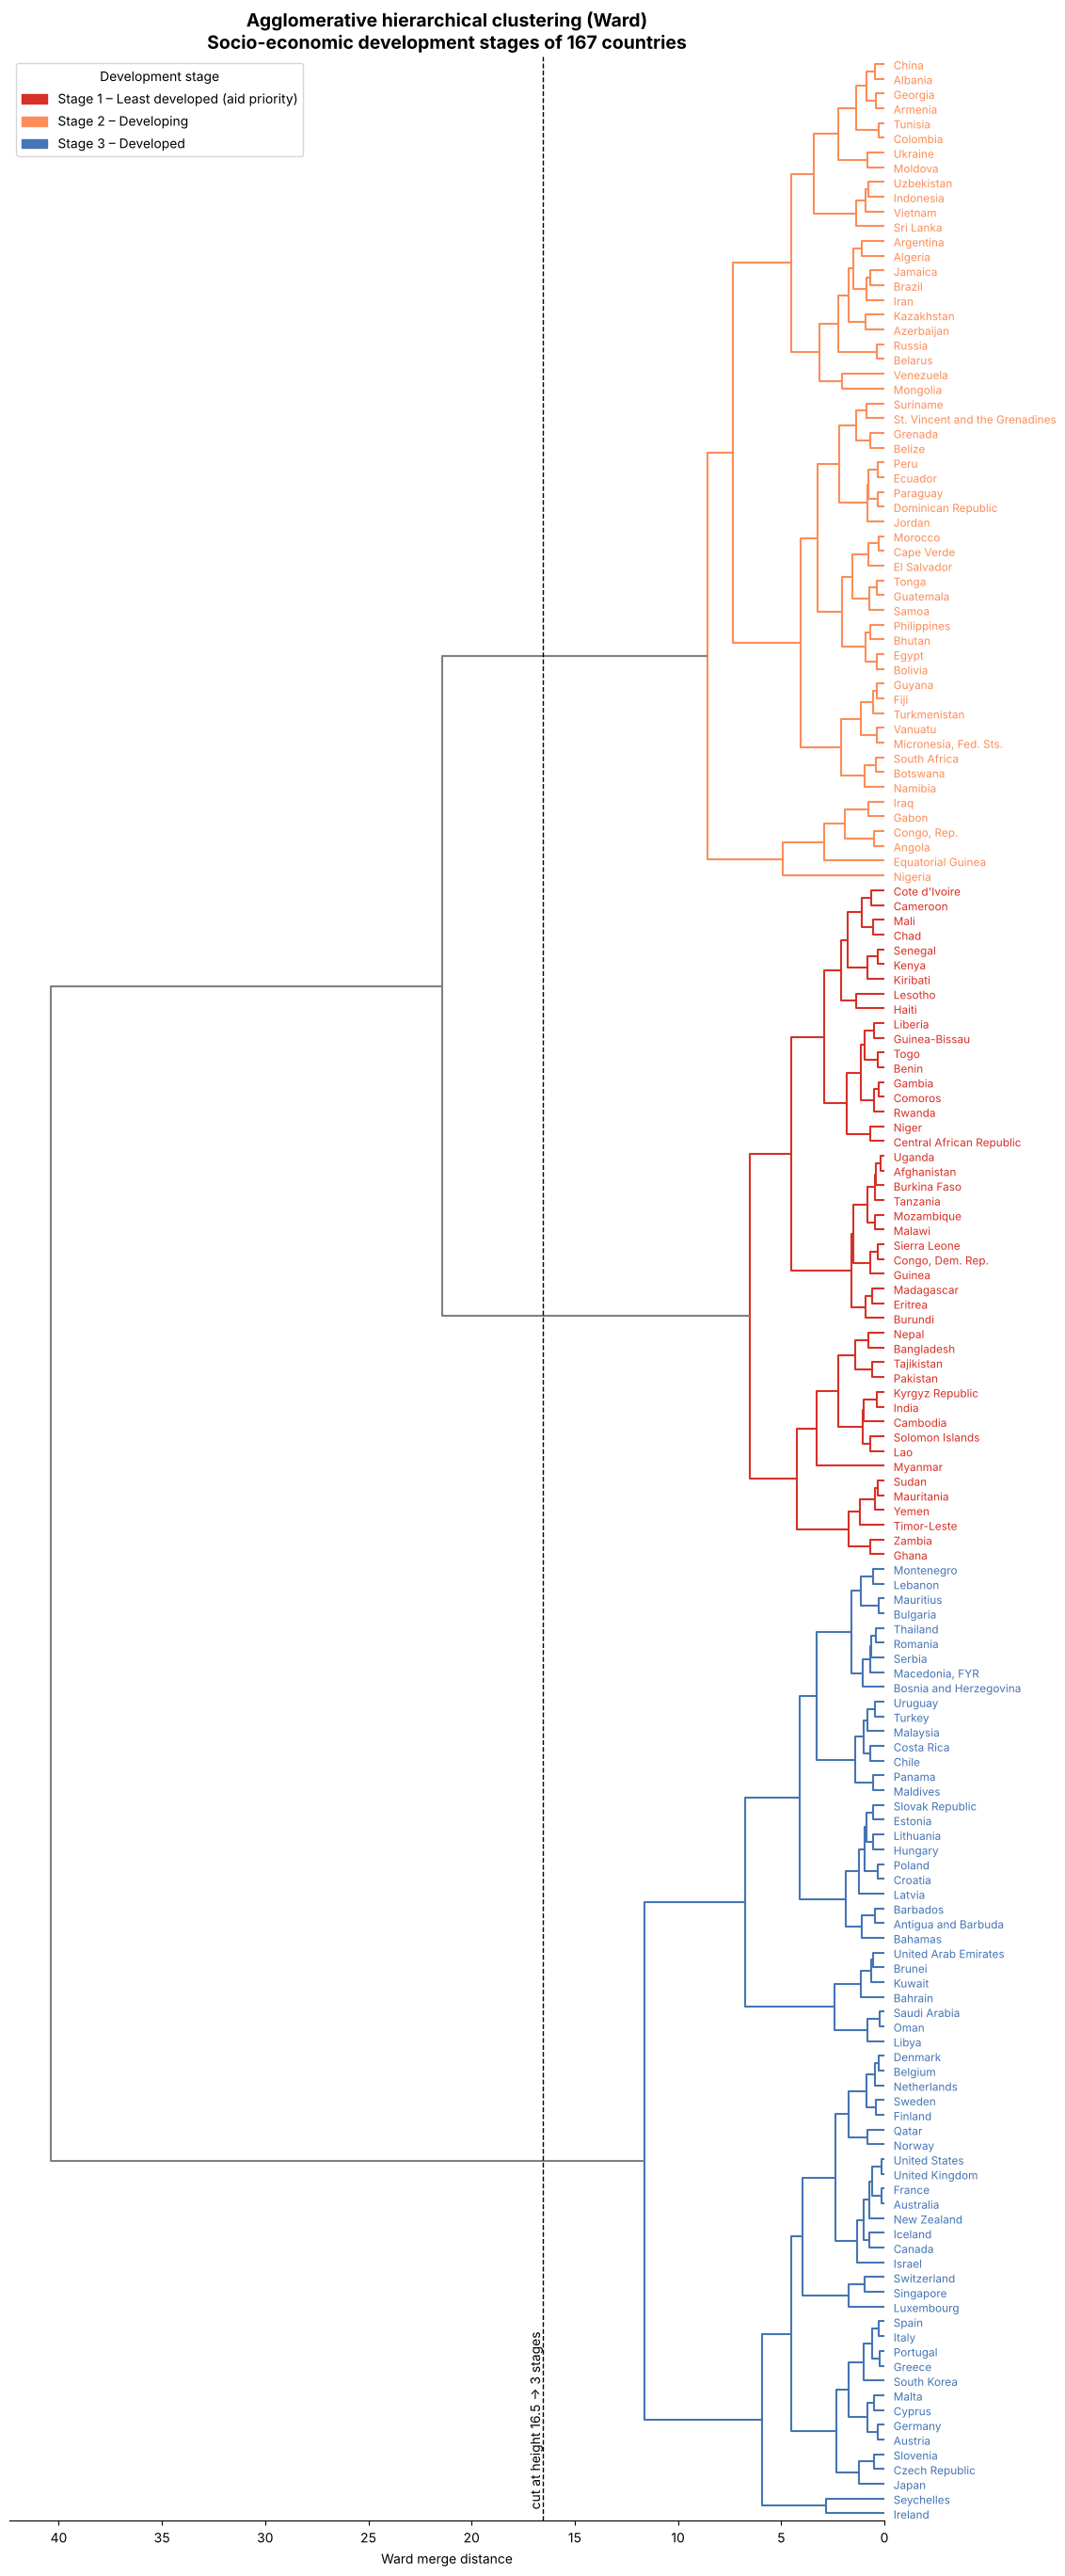

In [41]:
n = len(df_raw)
node_stage = {i: final_stage[i] for i in range(n)}
for j, (a, b, _, _) in enumerate(L_final):
    sa, sb = node_stage[int(a)], node_stage[int(b)]
    node_stage[n + j] = sa if sa == sb else None
link_color = lambda node: STAGE_COLORS.get(node_stage[node], "grey")
leaf_stage = dict(zip(df_raw["country"], final_stage))

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(12, 34))
    dendrogram(L_final, labels=df_raw["country"].values, orientation="left",
               link_color_func=link_color, leaf_font_size=8.5, ax=ax)
    for lbl in ax.get_yticklabels():
        lbl.set_color(STAGE_COLORS[leaf_stage[lbl.get_text()]])
    ax.axvline(cut, ls="--", color="black", lw=1)
    ax.text(cut, 5, f" cut at height {cut:.1f} → {K} stages ", fontsize=10,
            ha="right", va="bottom", rotation=90)
    ax.legend(handles=[Patch(color=STAGE_COLORS[s], label=STAGE_NAMES[s]) for s in STAGE_NAMES],
              loc="upper left", fontsize=10, title="Development stage")
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.set_title("Agglomerative hierarchical clustering (Ward)\n"
                 "Socio-economic development stages of 167 countries", fontsize=14, fontweight="bold")
    ax.set_xlabel("Ward merge distance")
    plt.show()

### 9.2 Truncated dendrogram

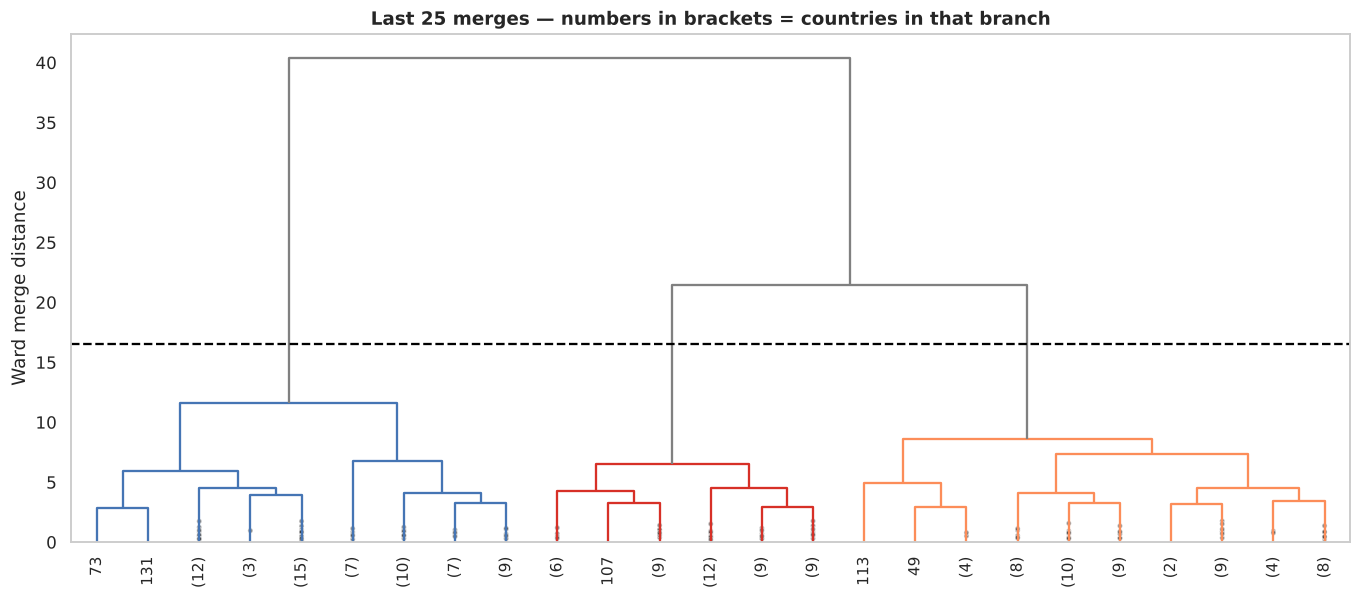

In [42]:
fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(L_final, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=10,
           show_contracted=True, link_color_func=link_color, ax=ax)
ax.axhline(cut, ls="--", color="black")
ax.grid(False)
ax.set(title="Last 25 merges — numbers in brackets = countries in that branch",
       ylabel="Ward merge distance")
plt.show()

### 9.3 Silhouette plot of the final model

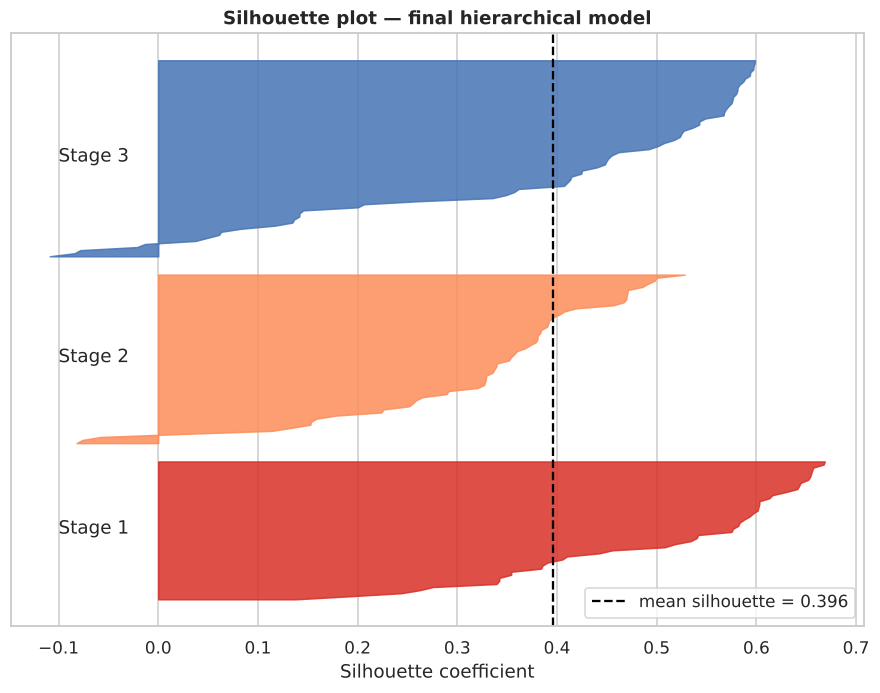

Borderline countries (negative silhouette): Angola, Congo, Rep., Libya, Macedonia, FYR, Nigeria, Serbia, Thailand, Turkey


In [43]:
sil = silhouette_samples(X_all, final_stage)
fig, ax = plt.subplots(figsize=(10, 7))
y = 0
for s in STAGE_NAMES:
    vals = np.sort(sil[final_stage == s])
    ax.fill_betweenx(np.arange(y, y + len(vals)), 0, vals, color=STAGE_COLORS[s], alpha=0.85)
    ax.text(-0.1, y + len(vals) / 2, f"Stage {s}", va="center")
    y += len(vals) + 5
ax.axvline(sil.mean(), ls="--", color="black", label=f"mean silhouette = {sil.mean():.3f}")
ax.set(title="Silhouette plot — final hierarchical model", xlabel="Silhouette coefficient", yticks=[])
ax.legend()
plt.show()
print("Borderline countries (negative silhouette):",
      ", ".join(df_raw.loc[sil < 0, "country"]))

### 9.4 Countries in PCA space by stage

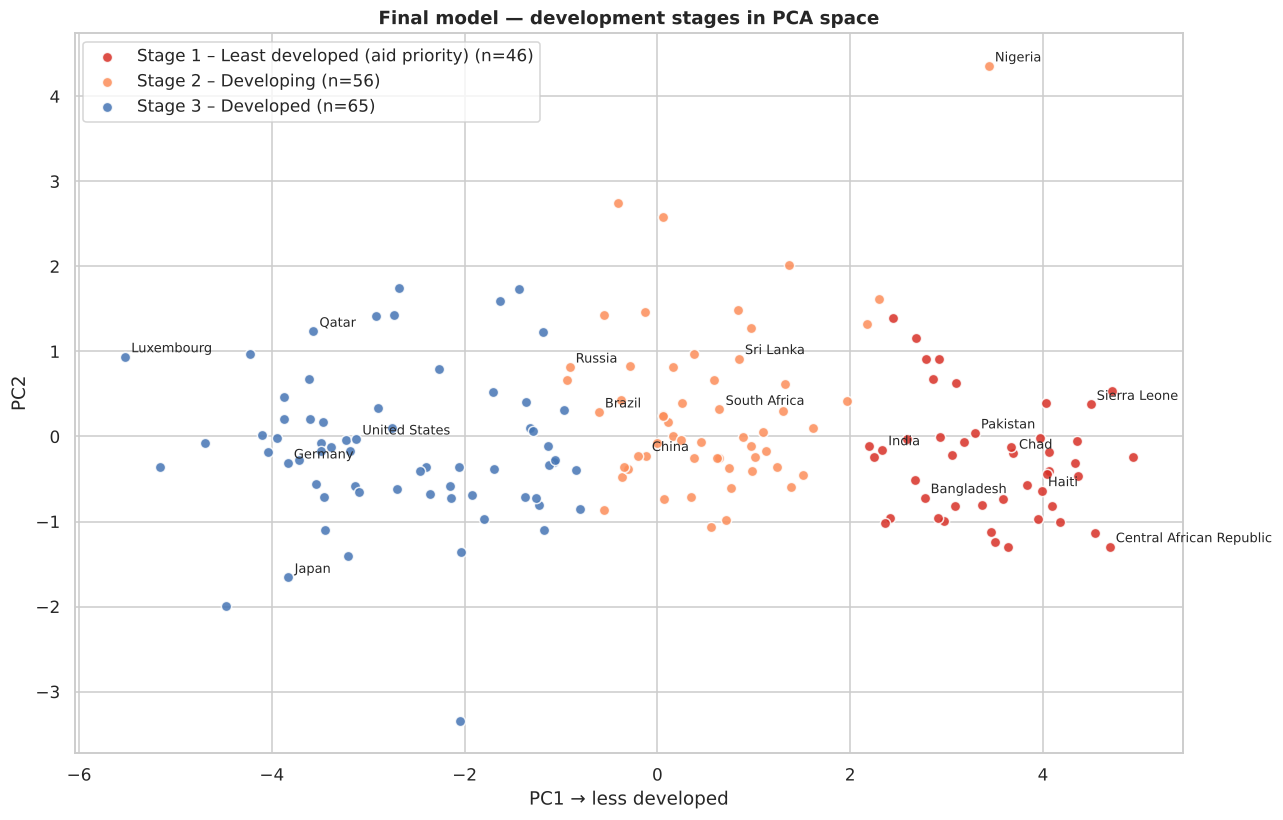

In [44]:
fig, ax = plt.subplots(figsize=(13, 8.5))
for s in STAGE_NAMES:
    m = final_stage == s
    ax.scatter(X_all[m, 0], X_all[m, 1], s=45, alpha=0.85, color=STAGE_COLORS[s],
               edgecolor="white", label=f"{STAGE_NAMES[s]} (n={m.sum()})")
for c in ["India", "China", "United States", "Nigeria", "Brazil", "Germany", "Haiti", "Chad",
          "Central African Republic", "Luxembourg", "Qatar", "Sierra Leone", "Bangladesh",
          "South Africa", "Japan", "Pakistan", "Russia", "Sri Lanka"]:
    i = df_raw.index[df_raw["country"] == c][0]
    ax.annotate(c, (X_all[i, 0], X_all[i, 1]), fontsize=8.5, xytext=(4, 3), textcoords="offset points")
ax.set(title="Final model — development stages in PCA space",
       xlabel="PC1 → less developed", ylabel="PC2")
ax.legend()
plt.show()

### 9.5 Stage profiles

In [45]:
profile = df_raw.groupby("stage")[features].median().round(2)
profile.insert(0, "countries", df_raw["stage"].value_counts())
profile

,countries,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
stage,,,,,,,,,,
Stage 1 – Least developed (aid priority),46,85.65,22.20,5.67,39.75,1835.0,7.39,60.8,5.00,748.0
Stage 2 – Developing,56,24.10,33.75,5.41,44.90,8510.0,8.09,71.3,2.60,3885.0
Stage 3 – Developed,65,6.20,49.60,7.96,46.20,29600.0,1.74,78.7,1.78,22100.0


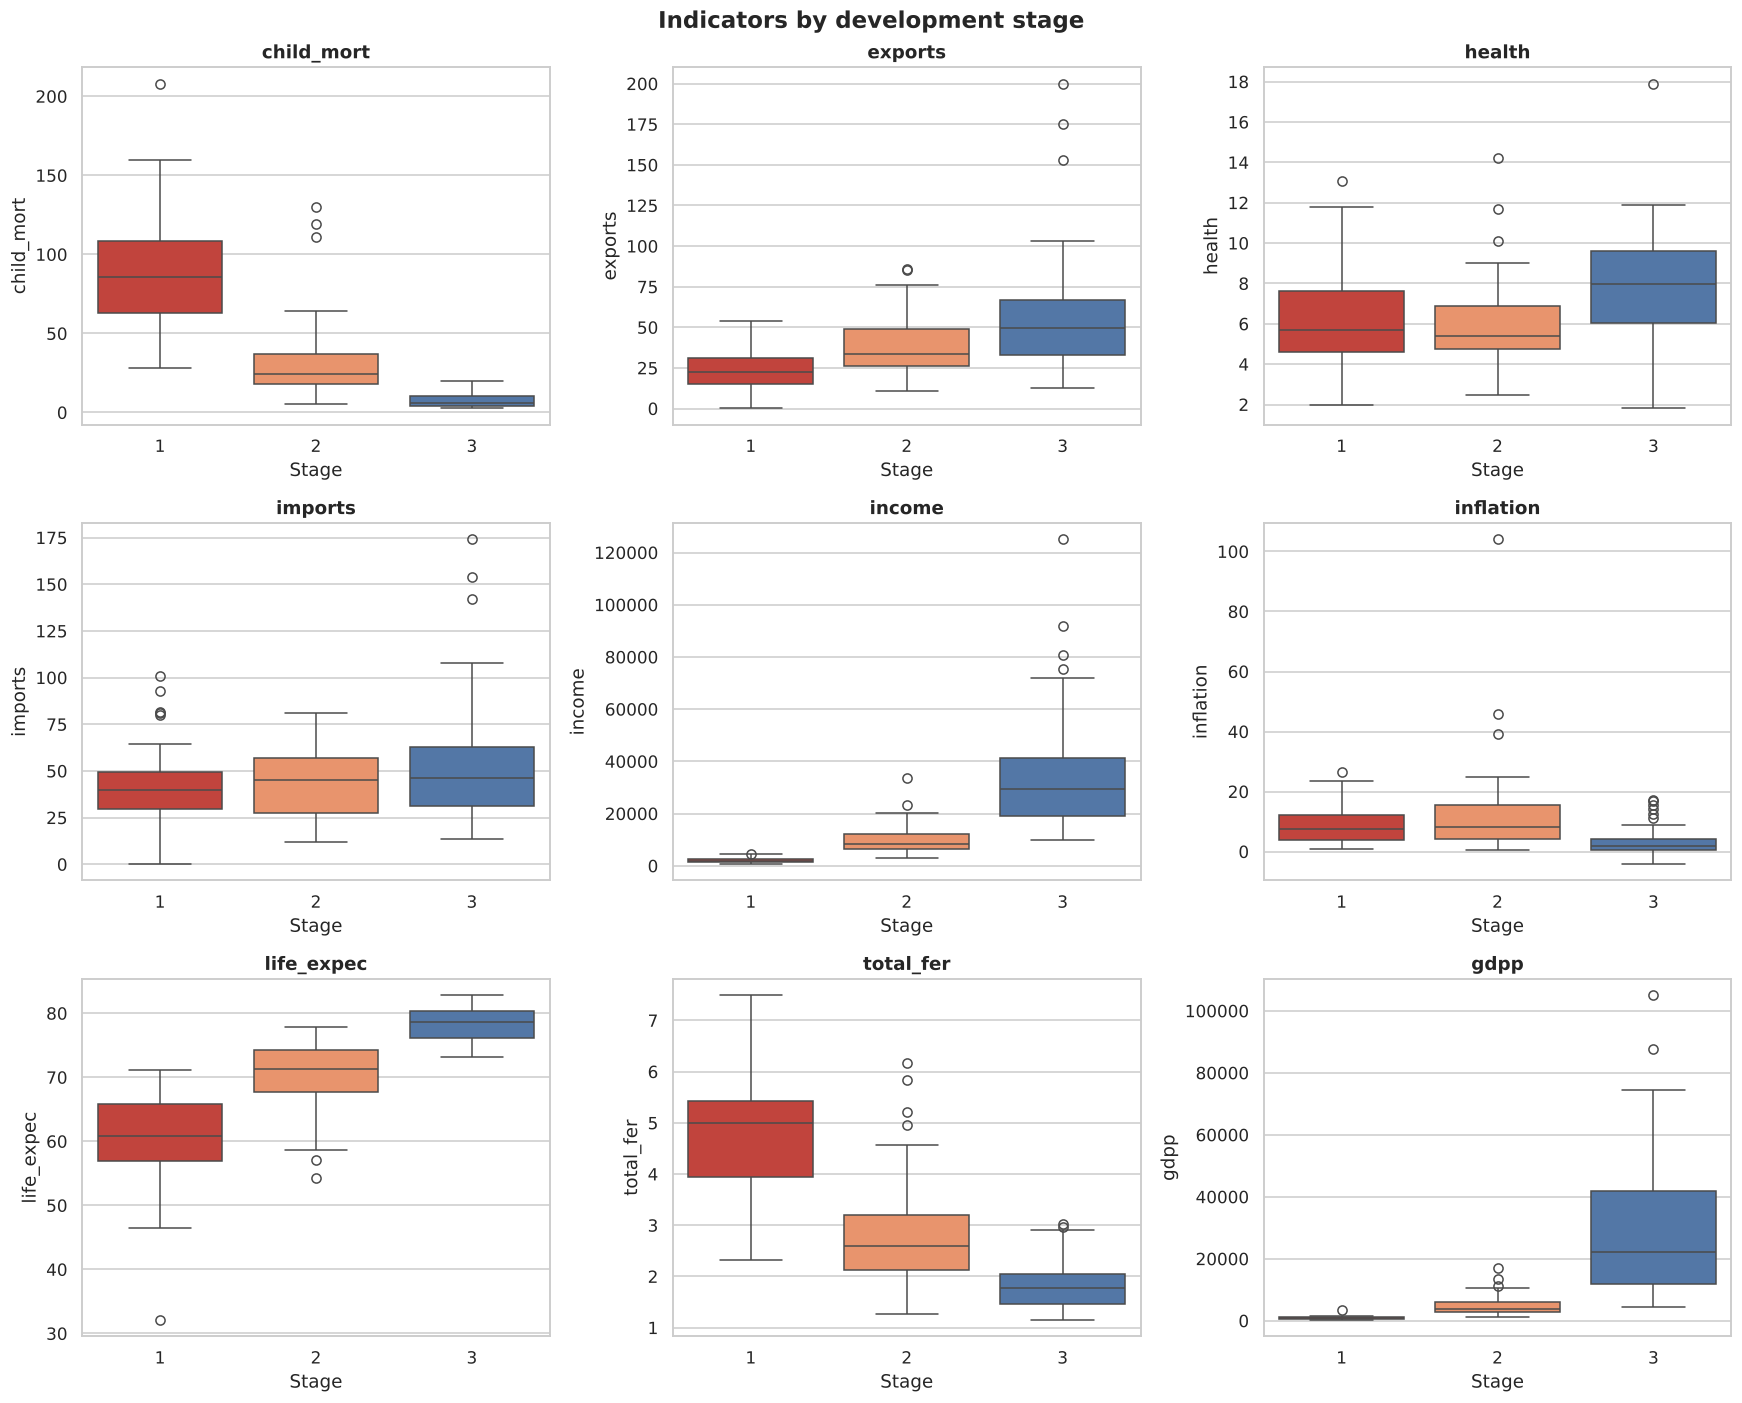

In [46]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df_raw, x="stage_id", y=col, hue="stage_id", palette=STAGE_COLORS,
                dodge=False, ax=ax, legend=False)
    ax.set(title=col, xlabel="Stage")
fig.suptitle("Indicators by development stage", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

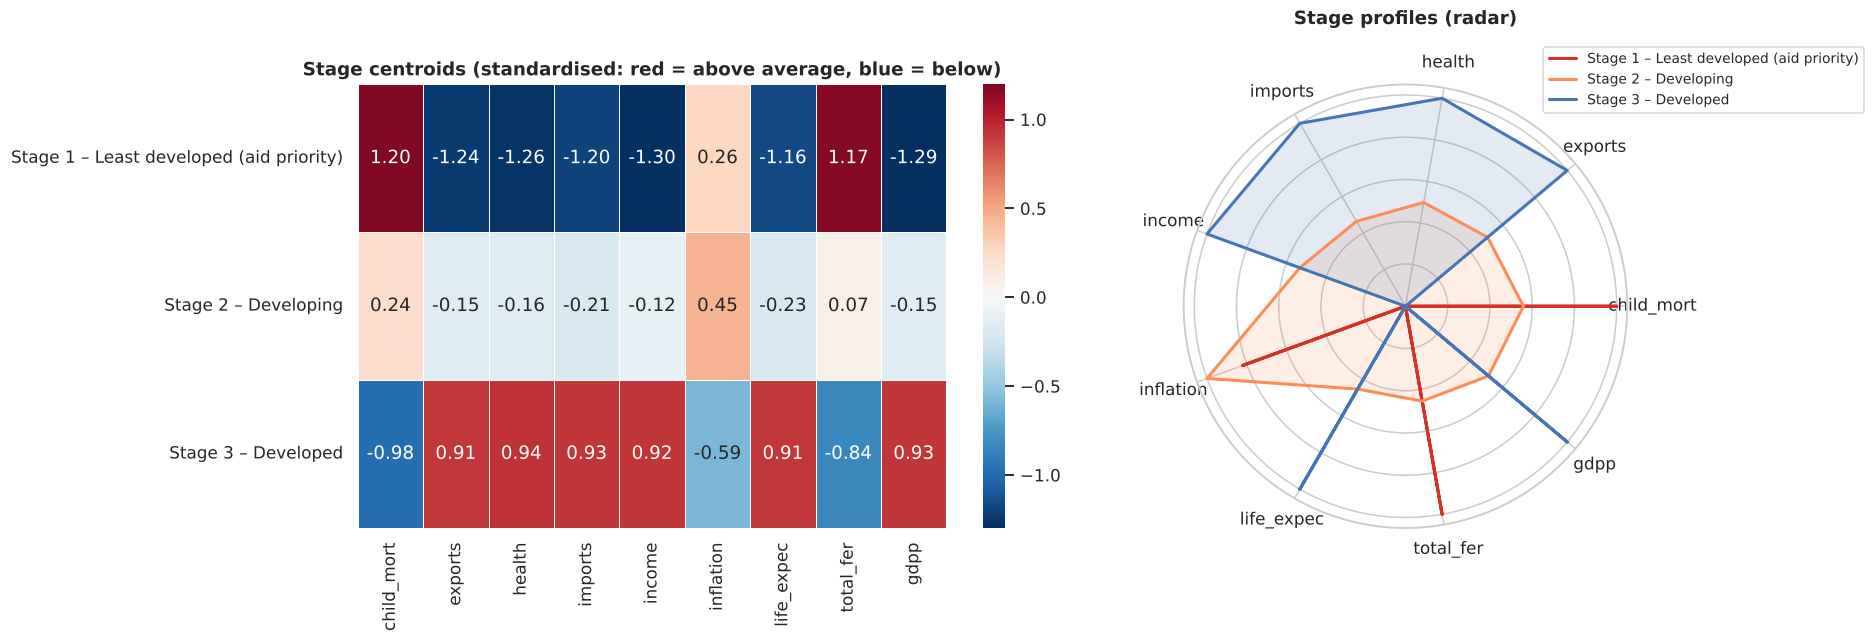

In [47]:
z = pd.DataFrame(pt.transform(df[features]), columns=features).groupby(final_stage).mean()
z.index = [STAGE_NAMES[i] for i in z.index]

fig = plt.figure(figsize=(18, 6))
ax1 = fig.add_subplot(1, 2, 1)
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5, ax=ax1)
ax1.set_title("Stage centroids (standardised: red = above average, blue = below)")

radar = (z - z.min()) / (z.max() - z.min())
angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist() + [0]
ax2 = fig.add_subplot(1, 2, 2, polar=True)
for s in STAGE_NAMES:
    vals = radar.loc[STAGE_NAMES[s]].tolist(); vals += vals[:1]
    ax2.plot(angles, vals, color=STAGE_COLORS[s], lw=2, label=STAGE_NAMES[s])
    ax2.fill(angles, vals, color=STAGE_COLORS[s], alpha=0.15)
ax2.set_xticks(angles[:-1]); ax2.set_xticklabels(features); ax2.set_yticklabels([])
ax2.set_title("Stage profiles (radar)", pad=20)
ax2.legend(loc="upper right", bbox_to_anchor=(1.55, 1.1), fontsize=9)
plt.tight_layout()
plt.show()

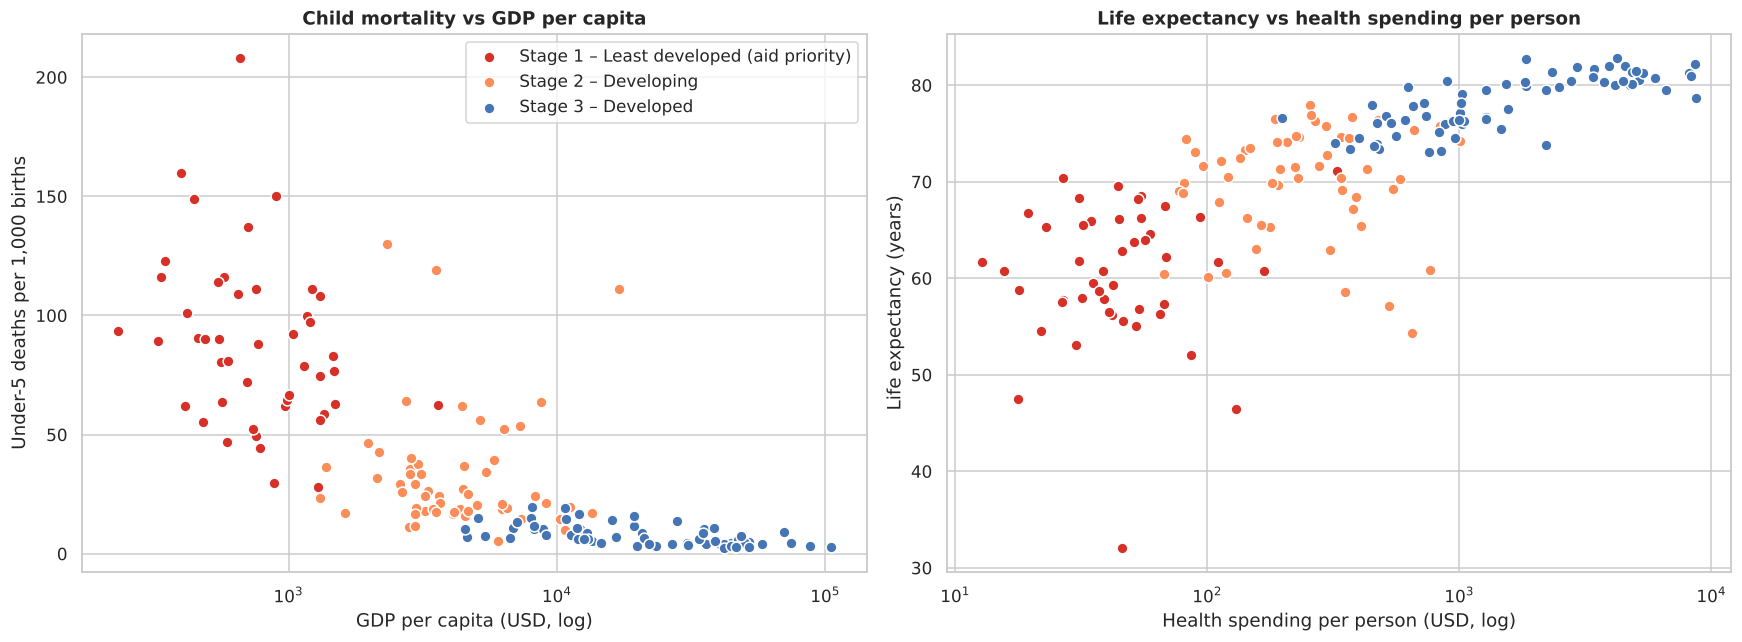

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for s in STAGE_NAMES:
    m = final_stage == s
    axes[0].scatter(df_raw.loc[m, "gdpp"], df_raw.loc[m, "child_mort"], c=STAGE_COLORS[s],
                    s=50, edgecolor="white", label=STAGE_NAMES[s])
    axes[1].scatter(df.loc[m, "health"], df_raw.loc[m, "life_expec"], c=STAGE_COLORS[s],
                    s=50, edgecolor="white")
axes[0].set(xscale="log", title="Child mortality vs GDP per capita",
            xlabel="GDP per capita (USD, log)", ylabel="Under-5 deaths per 1,000 births")
axes[0].legend()
axes[1].set(xscale="log", title="Life expectancy vs health spending per person",
            xlabel="Health spending per person (USD, log)", ylabel="Life expectancy (years)")
plt.tight_layout()
plt.show()

In [49]:
for s in STAGE_NAMES:
    members = sorted(df_raw.loc[final_stage == s, "country"])
    print(f"\n{STAGE_NAMES[s]}  ({len(members)} countries)\n" + ", ".join(members))


Stage 1 – Least developed (aid priority)  (46 countries)
Afghanistan, Bangladesh, Benin, Burkina Faso, Burundi, Cambodia, Cameroon, Central African Republic, Chad, Comoros, Congo, Dem. Rep., Cote d'Ivoire, Eritrea, Gambia, Ghana, Guinea, Guinea-Bissau, Haiti, India, Kenya, Kiribati, Kyrgyz Republic, Lao, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Mozambique, Myanmar, Nepal, Niger, Pakistan, Rwanda, Senegal, Sierra Leone, Solomon Islands, Sudan, Tajikistan, Tanzania, Timor-Leste, Togo, Uganda, Yemen, Zambia

Stage 2 – Developing  (56 countries)
Albania, Algeria, Angola, Argentina, Armenia, Azerbaijan, Belarus, Belize, Bhutan, Bolivia, Botswana, Brazil, Cape Verde, China, Colombia, Congo, Rep., Dominican Republic, Ecuador, Egypt, El Salvador, Equatorial Guinea, Fiji, Gabon, Georgia, Grenada, Guatemala, Guyana, Indonesia, Iran, Iraq, Jamaica, Jordan, Kazakhstan, Micronesia, Fed. Sts., Moldova, Mongolia, Morocco, Namibia, Nigeria, Paraguay, Peru, Philippines, Russia, Samoa, S

### 9.6 World map of development stages

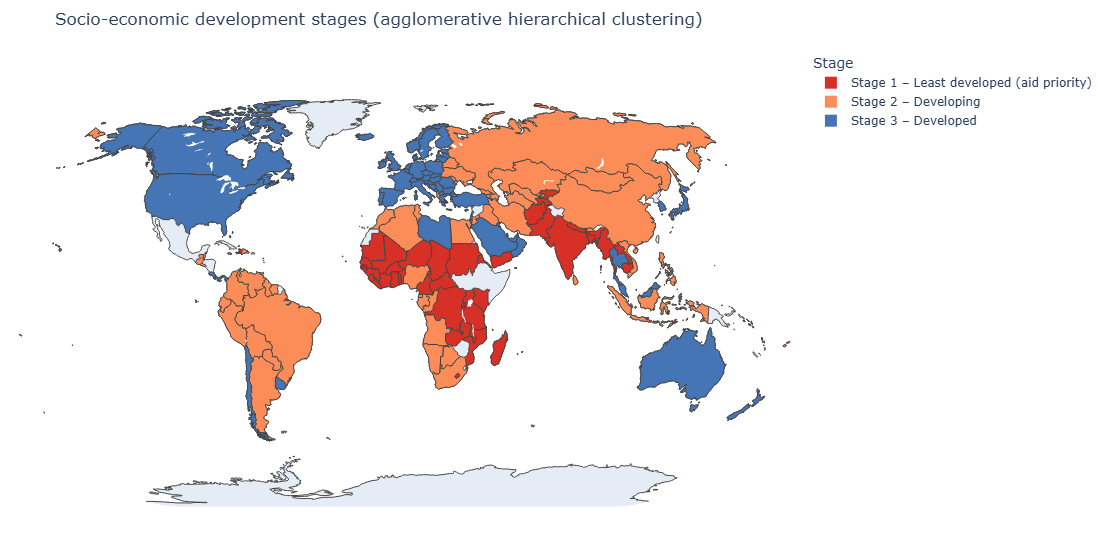

In [50]:
import plotly.express as px

fix = {"Congo, Dem. Rep.": "Democratic Republic of the Congo", "Congo, Rep.": "Republic of the Congo",
       "Cote d'Ivoire": "Côte d'Ivoire", "Kyrgyz Republic": "Kyrgyzstan", "Lao": "Laos",
       "Macedonia, FYR": "North Macedonia", "Micronesia, Fed. Sts.": "Micronesia",
       "Slovak Republic": "Slovakia", "St. Vincent and the Grenadines": "Saint Vincent and the Grenadines",
       "Timor-Leste": "East Timor", "Cape Verde": "Cabo Verde"}
map_df = df_raw[["country", "stage", "child_mort", "gdpp", "life_expec"]].copy()
map_df["map_name"] = map_df["country"].replace(fix)

fig = px.choropleth(map_df, locations="map_name", locationmode="country names", color="stage",
                    color_discrete_map={STAGE_NAMES[s]: STAGE_COLORS[s] for s in STAGE_NAMES},
                    category_orders={"stage": list(STAGE_NAMES.values())}, hover_name="country",
                    hover_data={"map_name": False, "child_mort": True, "gdpp": True, "life_expec": True},
                    title="Socio-economic development stages (agglomerative hierarchical clustering)")
fig.update_layout(height=550, margin=dict(l=0, r=0, t=50, b=0), legend_title_text="Stage")
fig.update_geos(showframe=False, projection_type="natural earth")
fig.show()

### 9.7 Targeted aid allocation
Inside Stage 1, countries are ranked by a **need score**: PC1 (the under-development axis) rescaled to 0–100. The budget split is an *illustration* of how the model output could drive an allocation rule (share ∝ need score). It is not a policy recommendation.

In [51]:
pc1 = X_all[:, 0]
df_raw["need_score"] = ((pc1 - pc1.min()) / (pc1.max() - pc1.min()) * 100).round(1)

priority = (df_raw[df_raw["stage_id"] == 1].sort_values("need_score", ascending=False)
            [["country", "need_score", "child_mort", "gdpp", "life_expec", "total_fer"]]
            .reset_index(drop=True))
priority.index += 1
BUDGET = 10_000_000
priority["illustrative_aid_usd"] = (priority["need_score"] / priority["need_score"].sum() * BUDGET).round(-3)
priority.head(15)

,country,need_score,child_mort,gdpp,life_expec,total_fer,illustrative_aid_usd
1,Burundi,100.0,93.6,231,57.7,6.26,253000.0
2,"Congo, Dem. Rep.",98.0,116.0,334,57.5,6.54,248000.0
3,Central African Republic,97.7,149.0,446,47.5,5.21,247000.0
4,Niger,96.3,123.0,348,58.8,7.49,244000.0
5,Sierra Leone,95.8,160.0,399,55.0,5.20,242000.0
6,Mozambique,94.6,101.0,419,54.5,5.56,239000.0
7,Malawi,94.4,90.5,459,53.1,5.31,239000.0
8,Eritrea,94.3,55.2,482,61.7,4.61,238000.0
9,Myanmar,92.8,64.4,988,66.8,2.41,235000.0
10,Liberia,92.0,89.3,327,60.8,5.02,233000.0


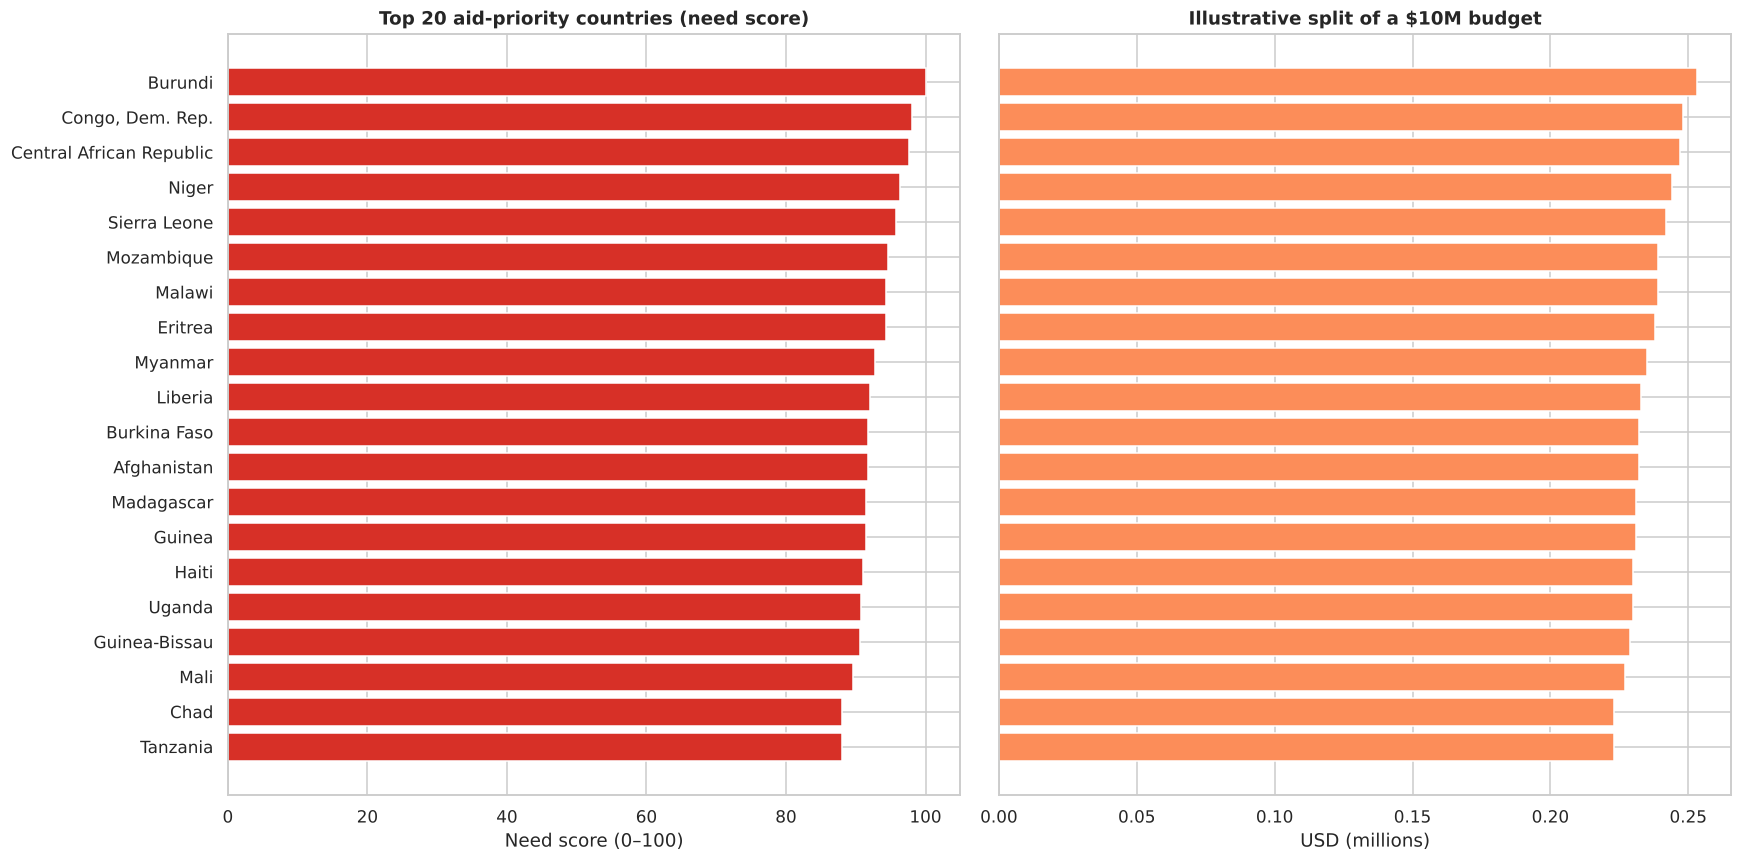

In [52]:
top = priority.head(20).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].barh(top["country"], top["need_score"], color="#d73027")
axes[0].set(title="Top 20 aid-priority countries (need score)", xlabel="Need score (0–100)")
axes[1].barh(top["country"], top["illustrative_aid_usd"] / 1e6, color="#fc8d59")
axes[1].set(title="Illustrative split of a $10M budget", xlabel="USD (millions)")
axes[1].set_yticklabels([])
plt.tight_layout()
plt.show()

### 9.8 Using the trained model on a new country
The trained pipeline (power transform → PCA → nearest hierarchical stage centroid) can classify any new country from its indicators.

In [53]:
def predict_stage(indicators: dict):
    row = pd.DataFrame([indicators])[features].astype(float)
    for col in ["exports", "health", "imports"]:          # same feature engineering as training
        row[col] = row[col] * row["gdpp"] / 100
    x = pca.transform(pt.transform(row))
    return STAGE_NAMES[int(hc_predict(x)[0])]

new_country = {"child_mort": 45.0, "exports": 25.0, "health": 4.5, "imports": 35.0, "income": 6000,
               "inflation": 6.0, "life_expec": 68.0, "total_fer": 3.2, "gdpp": 2500}
print("New country indicators:", new_country)
print("Predicted stage      :", predict_stage(new_country))

New country indicators: {'child_mort': 45.0, 'exports': 25.0, 'health': 4.5, 'imports': 35.0, 'income': 6000, 'inflation': 6.0, 'life_expec': 68.0, 'total_fer': 3.2, 'gdpp': 2500}
Predicted stage      : Stage 2 – Developing


### 9.9 Save the results

In [54]:
out = df_raw[["country", "stage", "need_score"] + features].sort_values("need_score", ascending=False)
out.to_csv("country_development_stages.csv", index=False)
priority.to_csv("aid_priority_stage1.csv")
results.to_csv("model_comparison.csv")
print("Saved: country_development_stages.csv, aid_priority_stage1.csv, model_comparison.csv")

Saved: country_development_stages.csv, aid_priority_stage1.csv, model_comparison.csv


## Step 10 — Conclusion

| Step | Outcome |
|---|---|
| Data | 167 countries, 9 indicators, no missing values; skewed money variables handled with a Yeo–Johnson transform |
| Feature engineering | exports, imports and health converted from % of GDP to USD per person |
| Split | 80 % train (133) / 20 % test (34), stratified on child-mortality level; transform and PCA fitted on train only |
| Latent dimensions | 4 principal components (≈ 97 % of variance); PC1 is an under-development axis |
| Main model | Agglomerative hierarchical clustering, Ward linkage, Euclidean distance, k = 3 |
| Comparison models | K-means and Gaussian Mixture (EM) |
| Evaluation | Test accuracy, confusion matrix, classification report, silhouette, Davies–Bouldin, Calinski–Harabasz, ARI |

**Development stages found**
* **Stage 1 – Least developed:** very high child mortality, very low GDP and health spending per person, short life expectancy, high fertility. This is the aid-priority group, ranked by need score.
* **Stage 2 – Developing:** middle income, moderate child mortality. Suited to targeted, programme-specific support.
* **Stage 3 – Developed:** high income and health outcomes. These are potential donor countries.

**Limitations:** the data is a single snapshot in time; all indicators are weighted equally; real aid decisions also depend on population, conflict and governance, which are not in this dataset; and because clustering is unsupervised, "accuracy" measures stability against the full-data model rather than agreement with an official label.